# 08 · The Crypt — Model Comparison and Error Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/08_error_analysis.ipynb)

Steps 2–6 built a **ladder of text representations**, from counts of words to contextual embeddings, and evaluated each model once on the test split. This notebook brings all models together and asks what is still wrong — and why.

1. **The final ledger** (§2): one table for all models in the order of the representation ladder, a significance test for every step up the ladder, and per-class F1.
2. **Confusion matrices** (§3) of the best model (fine-tuned BERT) and the TF-IDF + LR baseline.
3. **Error analysis** (§4): how the labels of the dataset were assigned, how much of the remaining error is annotation noise, a linguistic coding scheme for errors, and 18 annotated error examples.
4. **Disagreement analysis** (§5): the texts on which TF-IDF + LR and BERT disagree, and the words each model relies on.
5. **Behavioural tests** (§6): 60 hand-written sentences that probe negation, sarcasm, intensity and mixed emotions (Ribeiro et al., 2020), run through every model including the LLM.
6. **Export** (§7) of the results for the web application.

**Data use.** No model is trained or selected here. The test split was used once per model in Steps 2–6; this notebook only re-reads the saved predictions (`results/predictions/`) and describes the errors. Everything that is *learned* from data in this notebook — the keyword lexicon of §4 and the context classifiers of §4.2 — is fitted on the **training split only**.

## 0. Setup

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab provides the scientific packages; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /home/claude/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import json
import logging
import re
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

from src.behavioural import (CAPABILITIES, DIR_MARGIN, SUITE_PATH, group_tests, load_suite, score_items,
                             wilson_interval)
from src.config import (DATA_DIR, EMOTION_COLORS, FIG_DIR, ID2LABEL, LABEL2ID, LABELS, METRICS_DIR, MODELS_DIR,
                        NUM_LABELS, PRED_DIR, RESULTS_DIR, SEED, ensure_dirs, set_seed)
from src.data import load_splits, tokenize
from src.error_analysis import ERROR_CATEGORIES, code_errors, lr_contributions, occlusion
from src.evaluate import compute_metrics, load_record, mcnemar_test, paired_bootstrap
from src.keywords import KeywordLexicon, feel_complement
from src.llm import LLM_DIR, DeepSeekClassifier, load_prompt
from src.predictors import CLASSICAL_DIR, LADDER, MODEL_INFO, load_predictor, temperatures
from src.slices import (NEGATION_RE, TEMPLATE_LEVELS, has_negation, template_slice, training_vocabulary,
                        unseen_word_mask)

# PyTorch (loaded in §5-6) prints a notice that a distributed-training feature is unavailable on macOS; it is not used here.
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").addFilter(lambda record: False)
warnings.filterwarnings("ignore", message=".*Pandas4Warning.*")

set_seed(SEED)
ensure_dirs()
APP_DIR = RESULTS_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

LABEL_IDS = list(range(NUM_LABELS))
TEST_SUB = "test_subset300"
N_BOOT = 2000  # bootstrap resamples for paired comparisons (as in 07_llm_deepseek)
DISPLAY = {m: info["name"] for m, info in MODEL_INFO.items()}
SHORT = {"bow_nb": "BoW+NB", "bow_lr": "BoW+LR", "tfidf_lr": "TF-IDF+LR", "improved_lr": "Improved LR",
         "glove_lr": "GloVe+LR", "bilstm": "BiLSTM", "bert": "BERT", "llm": "LLM (few-shot)"}
STEP_COLORS = {"Step 2": "#9AA5B1", "Step 3": "#3B6BA5", "Step 4": "#E8A33D", "Step 5": "#C0392B", "Step 6": "#2A9D8F"}


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary metric: unweighted mean of the six per-class F1 scores.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled evaluation sets
    # (same procedure and seed as in Steps 2-6, so the intervals reproduce the saved ones).
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


def holm(p_values):
    # Holm step-down adjustment of a list of p-values (controls the family-wise error rate).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def fmt_ci(low, high):
    return f"[{low:+.3f}, {high:+.3f}]" if low < 0 or high < 0 else f"[{low:.3f}, {high:.3f}]"

## 1. Models and predictions

The seven trained models of the ladder are compared on the full test split (2,000 texts). The LLM (Step 6) was evaluated only on the fixed stratified subset of 300 test texts, so it enters every comparison through that subset. The role names follow the earlier steps: `glove_lr` is the GloVe Wikipedia 300d model, `bilstm` the BiLSTM on fine-tuned GloVe, `bert` the fine-tuned `bert-base-uncased` and `llm` DeepSeek with 18 demonstrations.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]
X_train, X_val, X_test = train["text"].tolist(), val["text"].tolist(), test["text"].tolist()
y_train, y_val, y_test = train["label"].to_numpy(), val["label"].to_numpy(), test["label"].to_numpy()
gold_test = test["label_name"].to_numpy(dtype=object)

PROBA_COLS = [f"p_{c}" for c in LABELS]
pred_frames, preds, probas = {}, {}, {}
for m in LADDER:
    frame = pd.read_csv(PRED_DIR / f"{m}__test.csv")
    # The saved predictions must be aligned row by row with the official test split.
    assert frame["text"].tolist() == X_test and np.array_equal(frame["true"].to_numpy(), y_test), m
    pred_frames[m], preds[m], probas[m] = frame, frame["pred"].to_numpy(), frame[PROBA_COLS].to_numpy()

records = {m: load_record(m, "test") for m in LADDER}
val_records = {m: load_record(m, "validation") for m in LADDER}

# The 300-text test subset of Step 6 (row indices into the test split).
subset = pd.read_csv(LLM_DIR / "test_subset300.csv")
sub_ids = subset["idx"].to_numpy()
y_sub = y_test[sub_ids]
sub_preds = {}
for m in LADDER + ["llm_zeroshot", "llm"]:
    frame = pd.read_csv(PRED_DIR / f"{m}__{TEST_SUB}.csv")
    assert frame["text"].tolist() == [X_test[i] for i in sub_ids], m
    sub_preds[m] = frame["pred"].to_numpy()
    if m in LADDER:  # the subset predictions of trained models are the full-test predictions restricted to the subset
        assert np.array_equal(sub_preds[m], preds[m][sub_ids]), m
llm_selection = json.loads((LLM_DIR / "selection.json").read_text())

registry = pd.DataFrame(MODEL_INFO).T.loc[LADDER + ["llm"]]
registry.insert(0, "model id", registry.index)
registry["evaluated on"] = ["test (2,000)"] * len(LADDER) + ["test subset (300)"]
display(registry.drop(columns="model id").rename_axis("model id"))
print(f"Test texts: {len(X_test):,} | subset: {len(sub_ids)} | LLM prompt: {llm_selection['selected_prompts']['llm_fewshot']} "
      f"(served model: {', '.join(llm_selection['served_models'])})")

,name,step,lecture,representation,pretrained,word_order,contextual,evaluated on
model id,,,,,,,,
bow_nb,BoW + Multinomial NB,Step 2,L5-L6,word counts,no,no,no,"test (2,000)"
bow_lr,BoW + LR,Step 2,L5-L6,word counts,no,no,no,"test (2,000)"
tfidf_lr,TF-IDF + LR,Step 2,L5-L6,TF-IDF,no,no,no,"test (2,000)"
improved_lr,"TF-IDF (sublinear) + LR, class weights",Step 3,L5-L6,"TF-IDF, sublinear tf",no,no,no,"test (2,000)"
glove_lr,GloVe mean + LR,Step 4,L6,"static word vectors, averaged",yes (static),no,no,"test (2,000)"
bilstm,BiLSTM (fine-tuned GloVe),Step 4,L7,"static word vectors, fine-tuned",yes (adapted),yes,no,"test (2,000)"
bert,BERT fine-tuned,Step 5,L8-L9,contextual WordPiece embeddings,yes (contextual),yes,yes,"test (2,000)"
llm,DeepSeek few-shot,Step 6,L9,prompted decoder-only LLM,yes (contextual),yes,yes,test subset (300)


Test texts: 2,000 | subset: 300 | LLM prompt: fs_random_k3 (served model: deepseek-flash)


## 2. The final ledger

### 2.1 All models along the representation ladder

Each row adds one property to the representation of a text: Naive Bayes → logistic regression changes the classifier on identical count features (a generative vs a discriminative log-linear model, Lecture 5); TF-IDF re-weights the counts (Lecture 6); Step 3 adds sublinear term frequency and class weights; GloVe replaces sparse word identities by dense pre-trained vectors (Lecture 6); the BiLSTM reads the words in order (Lecture 7); BERT makes every word representation depend on its context through self-attention (Lectures 8–9). Validation macro-F1 is the score the models were selected on; the test columns are the final evaluation. The 95% intervals are percentile bootstrap intervals of macro-F1 over 1,000 resampled test sets.

In [4]:
rows = []
for rung, m in enumerate(LADDER, start=1):
    rec, info = records[m], MODEL_INFO[m]
    low, high = bootstrap_ci(y_test, preds[m])
    rows.append({
        "rung": rung, "model id": m, "model": info["name"], "step": info["step"], "lecture": info["lecture"],
        "pre-trained": info["pretrained"], "word order": info["word_order"], "contextual": info["contextual"],
        "val macro-F1": val_records[m]["macro_f1"], "test accuracy": rec["accuracy"],
        "test macro-F1": rec["macro_f1"], "95% CI": f"[{low:.3f}, {high:.3f}]", "ci_low": low, "ci_high": high,
        "weighted-F1": rec["weighted_f1"],
    })
ledger = pd.DataFrame(rows).set_index("model id")
ledger["Δ macro-F1 vs previous rung"] = ledger["test macro-F1"].diff()
ledger.to_csv(METRICS_DIR / "final_ledger_test.csv")

best_val = ledger["val macro-F1"].idxmax()
print(f"Best model by validation macro-F1 (the selection criterion): {DISPLAY[best_val]} "
      f"({ledger.at[best_val, 'val macro-F1']:.4f})")
display(ledger.drop(columns=["ci_low", "ci_high", "lecture"]).style
        .format({"val macro-F1": "{:.3f}", "test accuracy": "{:.3f}", "test macro-F1": "{:.3f}",
                 "weighted-F1": "{:.3f}", "Δ macro-F1 vs previous rung": "{:+.3f}"}, na_rep="—")
        .background_gradient(subset=["test macro-F1"], cmap="Blues", vmin=0.5, vmax=0.95))

Best model by validation macro-F1 (the selection criterion): BERT fine-tuned (0.9224)


,rung,model,step,pre-trained,word order,contextual,val macro-F1,test accuracy,test macro-F1,95% CI,weighted-F1,Δ macro-F1 vs previous rung
model id,,,,,,,,,,,,
bow_nb,1,BoW + Multinomial NB,Step 2,no,no,no,0.719,0.801,0.695,"[0.667, 0.722]",0.792,—
bow_lr,2,BoW + LR,Step 2,no,no,no,0.856,0.883,0.831,"[0.808, 0.854]",0.882,+0.136
tfidf_lr,3,TF-IDF + LR,Step 2,no,no,no,0.865,0.881,0.832,"[0.808, 0.853]",0.880,+0.001
improved_lr,4,"TF-IDF (sublinear) + LR, class weights",Step 3,no,no,no,0.878,0.885,0.843,"[0.820, 0.862]",0.888,+0.011
glove_lr,5,GloVe mean + LR,Step 4,yes (static),no,no,0.642,0.674,0.601,"[0.573, 0.629]",0.671,-0.241
bilstm,6,BiLSTM (fine-tuned GloVe),Step 4,yes (adapted),yes,no,0.915,0.931,0.894,"[0.873, 0.911]",0.933,+0.292
bert,7,BERT fine-tuned,Step 5,yes (contextual),yes,yes,0.922,0.930,0.896,"[0.877, 0.911]",0.932,+0.002


The LLM can only be placed on the 300-text subset. The table below scores every model on these 300 texts, so the LLM rows are directly comparable with the trained models (the subset scores of the trained models differ slightly from their full-test scores; Step 6 showed that the subset is representative, Spearman ρ = 0.87 between subset and full-test scores).

,model,step,accuracy,macro-F1,95% CI
model id,,,,,
bow_nb,BoW + Multinomial NB,Step 2,0.837,0.731,"[0.655, 0.802]"
bow_lr,BoW + LR,Step 2,0.883,0.831,"[0.759, 0.883]"
tfidf_lr,TF-IDF + LR,Step 2,0.893,0.836,"[0.768, 0.892]"
improved_lr,"TF-IDF (sublinear) + LR, class weights",Step 3,0.890,0.840,"[0.775, 0.893]"
glove_lr,GloVe mean + LR,Step 4,0.707,0.650,"[0.568, 0.713]"
bilstm,BiLSTM (fine-tuned GloVe),Step 4,0.937,0.895,"[0.836, 0.942]"
bert,BERT fine-tuned,Step 5,0.943,0.925,"[0.879, 0.963]"
llm_zeroshot,DeepSeek zero-shot,Step 6,0.703,0.662,"[0.598, 0.722]"
llm,DeepSeek few-shot,Step 6,0.753,0.713,"[0.647, 0.774]"


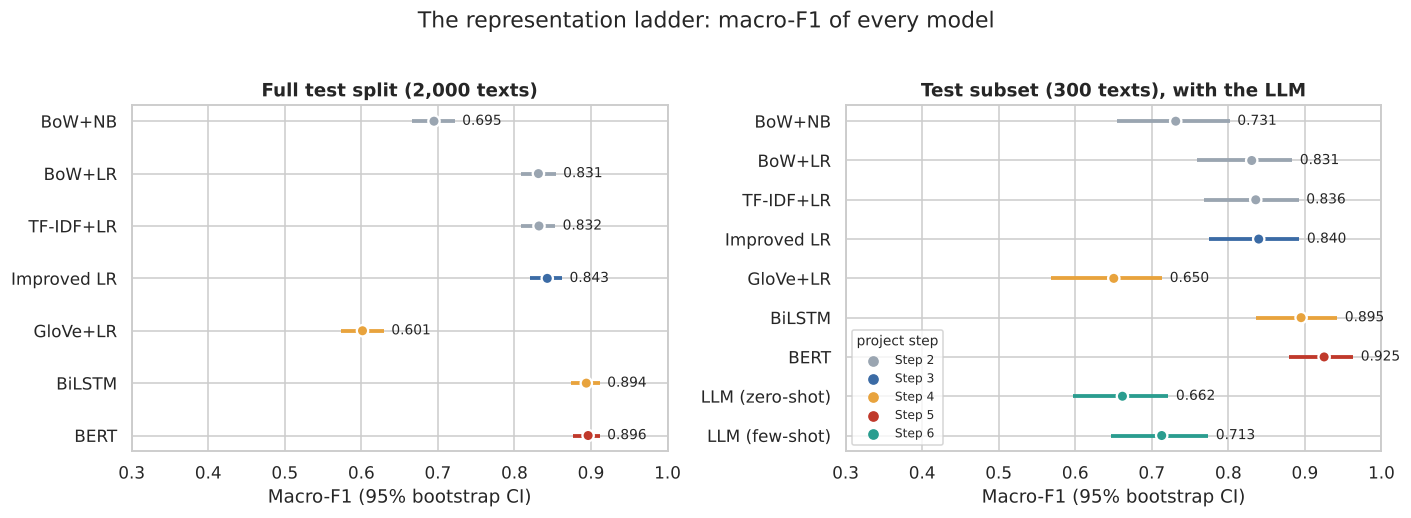

In [5]:
sub_rows = []
for m in LADDER + ["llm_zeroshot", "llm"]:
    low, high = bootstrap_ci(y_sub, sub_preds[m])
    name = DISPLAY.get(m, "DeepSeek zero-shot")
    sub_rows.append({"model id": m, "model": name,
                     "step": MODEL_INFO.get(m, MODEL_INFO["llm"])["step"],
                     "accuracy": float(np.mean(sub_preds[m] == y_sub)), "macro-F1": macro_f1(y_sub, sub_preds[m]),
                     "ci_low": low, "ci_high": high})
ledger_sub = pd.DataFrame(sub_rows).set_index("model id")
ledger_sub["95% CI"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(ledger_sub.ci_low, ledger_sub.ci_high)]
display(ledger_sub.drop(columns=["ci_low", "ci_high"]).style.format({"accuracy": "{:.3f}", "macro-F1": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1]}, sharey=False)
for ax, table, title, models in [
    (axes[0], ledger.rename(columns={"test macro-F1": "macro-F1"}), "Full test split (2,000 texts)", LADDER),
    (axes[1], ledger_sub, "Test subset (300 texts), with the LLM", LADDER + ["llm_zeroshot", "llm"]),
]:
    y = np.arange(len(models))[::-1]
    steps = [MODEL_INFO.get(m, MODEL_INFO["llm"])["step"] for m in models]
    colors = [STEP_COLORS[s] for s in steps]
    ax.hlines(y, table.loc[models, "ci_low"], table.loc[models, "ci_high"], color=colors, lw=2.5)
    ax.scatter(table.loc[models, "macro-F1"], y, color=colors, s=55, zorder=3, edgecolor="white", linewidth=1.5)
    for yi, m in zip(y, models):
        ax.text(table.at[m, "ci_high"] + 0.01, yi, f"{table.at[m, 'macro-F1']:.3f}", va="center", fontsize=9)
    ax.set_yticks(y, [SHORT.get(m, "LLM (zero-shot)") for m in models])
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("Macro-F1 (95% bootstrap CI)")
    ax.set_title(title)
for step, color in STEP_COLORS.items():
    axes[1].scatter([], [], color=color, label=step)
axes[1].legend(loc="lower left", title="project step", fontsize=8, title_fontsize=9)
fig.suptitle("The representation ladder: macro-F1 of every model", y=1.02)
fig.tight_layout()
savefig(fig, "crypt_ledger.png")
plt.show()

**Interpretation.** Fine-tuned BERT is the best model by the selection criterion (validation macro-F1 0.922) and also on the test split (macro-F1 0.896, accuracy 0.930), but the BiLSTM is practically level with it (0.894); their confidence intervals overlap almost completely. The ladder is **not monotonic**. Two steps produce large gains — replacing Naive Bayes by logistic regression on the same counts (+0.136) and moving from averaged static vectors to a recurrent encoder (+0.292) — while averaging GloVe vectors loses 0.241 against the sparse model below it: the mean of 300-dimensional vectors blurs the one word that carries the label (Step 4). TF-IDF weighting, sublinear term frequency and class weights change macro-F1 by at most 0.011.

On the 300-text subset the few-shot LLM (0.713) ranks below every trained model except GloVe + LR (0.650), and close to Naive Bayes (0.731; a difference well inside the intervals). With only 300 texts the intervals are about 2.5 times wider than on the full test split.

### 2.2 Is each step up the ladder significant?

Every model is compared with the rung directly below it, on the same texts: **McNemar's test** on the texts where exactly one of the two models is correct (b = only the lower rung correct, c = only the higher rung correct) and a **paired bootstrap** of the macro-F1 difference (2,000 resamples). The two tests answer different questions — McNemar's test concerns accuracy (the count of discordant texts), the bootstrap concerns macro-F1, in which the minority classes weigh more. Two comparisons are added: the overall gain from the baseline to the best model (TF-IDF + LR → BERT), and the last rung, BERT → LLM, which can only be tested on the 300-text subset. The eight p-values form one family and are adjusted with the Holm procedure.

In [6]:
comparisons = [(LADDER[i], LADDER[i + 1], "test") for i in range(len(LADDER) - 1)]
comparisons += [("tfidf_lr", "bert", "test"), ("bert", "llm", TEST_SUB)]
questions = {
    ("bow_nb", "bow_lr"): "generative -> discriminative classifier (same counts)",
    ("bow_lr", "tfidf_lr"): "raw counts -> TF-IDF weights",
    ("tfidf_lr", "improved_lr"): "+ sublinear tf and class weights",
    ("improved_lr", "glove_lr"): "sparse word identities -> averaged static vectors",
    ("glove_lr", "bilstm"): "+ word order (recurrent encoder), fine-tuned vectors",
    ("bilstm", "bert"): "+ contextual self-attention, pre-trained encoder",
    ("tfidf_lr", "bert"): "baseline -> best model (overall gain)",
    ("bert", "llm"): "fine-tuned encoder -> prompted decoder-only LLM",
}
sig_rows = []
for a, b, split in comparisons:
    if split == "test":
        yt, pa, pb = y_test, preds[a], preds[b]
    else:
        yt, pa, pb = y_sub, sub_preds[a], sub_preds[b]
    mc = mcnemar_test(yt, pa, pb)
    bs = paired_bootstrap(yt, pa, pb, n_boot=N_BOOT, seed=SEED)
    sig_rows.append({"comparison (A → B)": f"{SHORT[a]} → {SHORT[b]}", "question": questions[(a, b)],
                     "texts": len(yt), "b (only A correct)": mc["b"], "c (only B correct)": mc["c"],
                     "McNemar p": mc["p_value"], "Δ macro-F1 (B − A)": bs["delta"],
                     "95% CI of Δ": fmt_ci(bs["ci_low"], bs["ci_high"]), "a": a, "b_id": b})
significance = pd.DataFrame(sig_rows)
significance["Holm p"] = holm(significance["McNemar p"])
significance["significant (Holm, 0.05)"] = np.where(significance["Holm p"] < 0.05, "yes", "no")
significance.drop(columns=["a", "b_id"]).to_csv(METRICS_DIR / "significance_ladder_test.csv", index=False)
display(significance.drop(columns=["a", "b_id"]).style.format(
    {"McNemar p": "{:.2g}", "Holm p": "{:.2g}", "Δ macro-F1 (B − A)": "{:+.3f}"}).hide(axis="index"))

comparison (A → B),question,texts,b (only A correct),c (only B correct),McNemar p,Δ macro-F1 (B − A),95% CI of Δ,Holm p,"significant (Holm, 0.05)"
BoW+NB → BoW+LR,generative -> discriminative classifier (same counts),2000,75,238,5.3e-20,+0.136,"[0.105, 0.169]",3.2e-19,yes
BoW+LR → TF-IDF+LR,raw counts -> TF-IDF weights,2000,38,35,0.81,+0.001,"[-0.013, +0.014]",1,no
TF-IDF+LR → Improved LR,+ sublinear tf and class weights,2000,71,78,0.62,+0.011,"[-0.010, +0.031]",1,no
Improved LR → GloVe+LR,sparse word identities -> averaged static vectors,2000,497,76,6.4e-69,-0.241,"[-0.270, -0.211]",4.5e-68,yes
GloVe+LR → BiLSTM,"+ word order (recurrent encoder), fine-tuned vectors",2000,47,561,3.9e-96,+0.292,"[0.262, 0.322]",3.1e-95,yes
BiLSTM → BERT,"+ contextual self-attention, pre-trained encoder",2000,55,52,0.85,+0.002,"[-0.013, +0.017]",1,no
TF-IDF+LR → BERT,baseline -> best model (overall gain),2000,66,163,2.2e-10,+0.064,"[0.040, 0.087]",9e-10,yes
BERT → LLM (few-shot),fine-tuned encoder -> prompted decoder-only LLM,300,63,6,1.6e-11,-0.212,"[-0.284, -0.145]",7.8e-11,yes


**Interpretation.** Three of the six steps up the ladder are significant after the Holm adjustment: the discriminative classifier (75 texts lost, 238 gained) and the sequence model over averaged vectors (47 vs 561) in the expected direction, and averaged GloVe vectors against sparse features (497 vs 76) in the opposite one. Three steps are **not** significant: TF-IDF weighting (38 vs 35), the Step 3 improvements (71 vs 78) and, most notably, **contextual self-attention on top of the BiLSTM** (55 vs 52, p = 0.85; Δ macro-F1 +0.002 [−0.013, +0.017]). The overall gain from the baseline to the best model is clear: BERT corrects 163 texts that TF-IDF + LR gets wrong and loses 66 (Δ +0.064 [+0.040, +0.087]). The prompted LLM falls significantly below BERT on the same 300 texts (6 vs 63, Δ −0.212).

A non-significant step does not show that the two representations are equivalent in general; it shows that this test set cannot separate them. §4 explains why: most of the errors that remain for the two strongest models lie on texts whose label cannot be recovered from the text, so the room for any further representation to improve is very small.

### 2.3 Per-class F1

Macro-F1 hides which classes improve. The heat map shows F1 per class for every model; the column labels give the number of test texts per class (the minority classes *love* and *surprise* have 159 and 66).

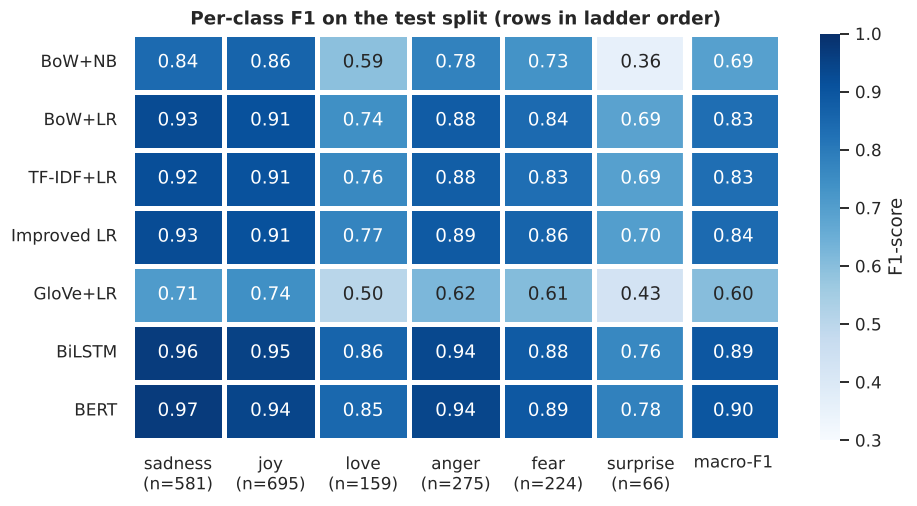

,sadness,joy,love,anger,fear,surprise
BERT − TF-IDF+LR,+0.050,+0.034,+0.088,+0.065,+0.060,+0.088


In [7]:
per_class = pd.DataFrame({m: {c: records[m]["per_class"][c]["f1"] for c in LABELS} for m in LADDER}).T
support = {c: records["bert"]["per_class"][c]["support"] for c in LABELS}
per_class["macro-F1"] = [records[m]["macro_f1"] for m in LADDER]
per_class.to_csv(METRICS_DIR / "final_per_class_f1_test.csv")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
show = per_class.copy()
show.index = [SHORT[m] for m in LADDER]
show.columns = [f"{c}\n(n={support[c]})" for c in LABELS] + ["macro-F1"]
sns.heatmap(show, annot=True, fmt=".2f", cmap="Blues", vmin=0.3, vmax=1.0, linewidths=2, linecolor="white",
            cbar_kws={"label": "F1-score"}, ax=ax)
ax.axvline(NUM_LABELS, color="white", lw=6)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Per-class F1 on the test split (rows in ladder order)")
ax.tick_params(axis="x", rotation=0)
savefig(fig, "crypt_per_class_f1.png")
plt.show()

gain = (per_class.loc["bert", LABELS] - per_class.loc["tfidf_lr", LABELS]).rename("BERT − TF-IDF+LR")
display(gain.to_frame().T.style.format("{:+.3f}"))

**Interpretation.** All models find *sadness* and *joy* easiest, the two largest classes (581 and 695 test texts). The minority classes separate the rungs: *surprise* rises from 0.36 (Naive Bayes, whose additive smoothing gives the rare class little probability mass) to 0.69 with logistic regression and 0.78 with BERT, and *love* from 0.59 to 0.85. BERT's gains over TF-IDF + LR are largest exactly there (+0.088 for both *love* and *surprise*) and smallest for *joy* (+0.034). Because macro-F1 weights every class equally, these two minority classes account for a large part of the difference in macro-F1 between the rungs. GloVe + LR is weak in every class, not only in the rare ones: averaging hurts the representation itself, not just the class balance.

## 3. Confusion matrices: the best model and the baseline

Rows are gold labels and columns predictions; each row is normalised to sum to 1, so the diagonal is the recall of each class. The third panel subtracts the baseline from BERT: blue cells gained probability mass under BERT, red cells lost it. A good model shows blue on the diagonal and red off it.

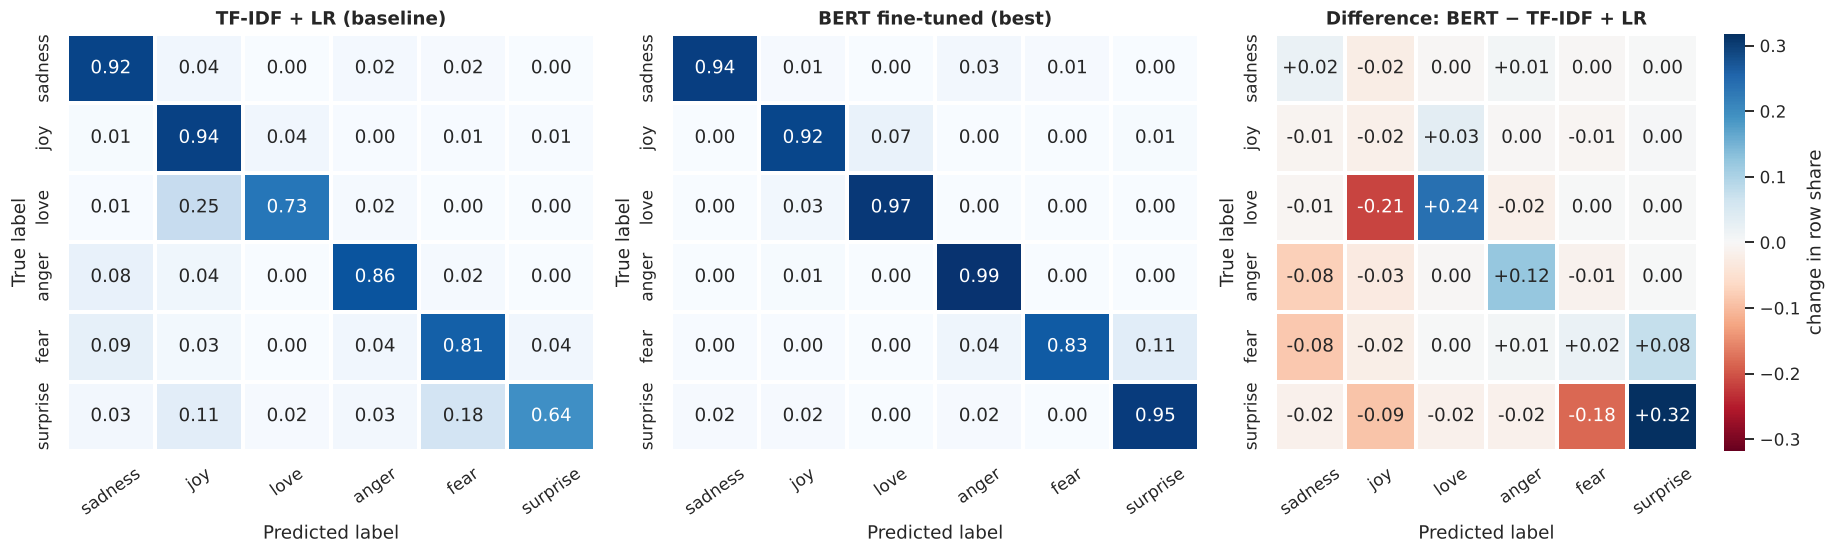

model              TF-IDF+LR  BERT
gold    predicted                 
joy     love              26    50
love    joy               39     5
fear    surprise           8    25
sadness anger             13    18
        joy               21     8
anger   sadness           21     0
fear    sadness           20     1
        anger              8    10

Errors: TF-IDF + LR 237, BERT 140


In [8]:
def row_normalised(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS).astype(float)
    return cm / cm.sum(axis=1, keepdims=True)


cm_bert, cm_lr = row_normalised(y_test, preds["bert"]), row_normalised(y_test, preds["tfidf_lr"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, cm, title in [(axes[0], cm_lr, "TF-IDF + LR (baseline)"), (axes[1], cm_bert, "BERT fine-tuned (best)")]:
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=1.5,
                linecolor="white", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
diff = cm_bert - cm_lr
limit = np.abs(diff).max()
annot = np.vectorize(lambda v: "0.00" if abs(v) < 0.005 else f"{v:+.2f}")(diff)
sns.heatmap(diff, annot=annot, fmt="", cmap="RdBu", norm=TwoSlopeNorm(0, -limit, limit), linewidths=1.5,
            linecolor="white", xticklabels=LABELS, yticklabels=LABELS, ax=axes[2],
            cbar_kws={"label": "change in row share"})
axes[2].set_title("Difference: BERT − TF-IDF + LR")
axes[2].set_xlabel("Predicted label")
axes[2].set_ylabel("True label")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
savefig(fig, "crypt_confusion_bert_vs_tfidf.png")
plt.show()

confusions = []
for m in ["tfidf_lr", "bert"]:
    counts = confusion_matrix(y_test, preds[m], labels=LABEL_IDS)
    for i in LABEL_IDS:
        for j in LABEL_IDS:
            if i != j:
                confusions.append({"model": SHORT[m], "gold": LABELS[i], "predicted": LABELS[j],
                                   "texts": int(counts[i, j]), "share of gold class": counts[i, j] / counts[i].sum()})
confusions = pd.DataFrame(confusions)
top_pairs = (confusions.pivot_table(index=["gold", "predicted"], columns="model", values="texts")
             .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False).head(8))
display(top_pairs[[SHORT["tfidf_lr"], SHORT["bert"]]].astype(int))
print(f"Errors: TF-IDF + LR {int((preds['tfidf_lr'] != y_test).sum())}, BERT {int((preds['bert'] != y_test).sum())}")

**Interpretation.** The baseline's two largest confusions are *love → joy* (25% of the love texts) and *surprise → fear* (18%); BERT reduces them to 3% and 0% and raises the recall of *love* from 0.73 to 0.97 and of *surprise* from 0.64 to 0.95. It also removes the drift of *anger* and *fear* towards *sadness* (8–9% → 0%). But BERT does not simply make fewer errors of every kind: it makes **more** errors in the opposite direction of the same pairs — *joy → love* rises from 26 to 50 texts and *fear → surprise* from 8 to 25. The model has moved the boundary between each pair of neighbouring classes rather than sharpened it. §4.2 shows why these particular pairs remain: they are the pairs between which the dataset's split keywords (*blessed*, *passionate*, *supporting* for joy/love; *weird*, *strange*, *overwhelmed* for fear/surprise) are divided.

## 4. Error analysis

### 4.1 How were the labels assigned? The emotion keyword

dair-ai/emotion is the English Twitter corpus of Saravia et al. (2018). Its texts were not annotated one by one: they were collected with emotion-word hashtags and labelled automatically (distant supervision). Two facts from `01_eda` point the same way: 97.3% of the training texts contain a form of *feel*, and the word after it usually names the emotion. If the labels were derived from that word, a classifier that reads **only one word** should already do well.

`src/keywords.py` takes the first content word after *feel / feels / feeling / felt* (skipping intensifiers and hedges such as *so*, *a little*, *kind of*) as the text's **emotion keyword**, counts the labels of each keyword in the training split, and keeps the keywords that occur at least 10 times. The **look-up classifier** predicts the training majority label of the keyword; texts without a known keyword receive no prediction.

In [9]:
lexicon = KeywordLexicon().fit(X_train, train["label_name"].tolist())
kw_table = lexicon.table_
kw_table.to_csv(METRICS_DIR / "keyword_lexicon_train.csv")

lookup_rows = []
for split_name, texts, y_split in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    gold = np.array([ID2LABEL[y] for y in y_split], dtype=object)
    guess = np.array(lexicon.predict(texts), dtype=object)
    covered = np.array([g is not None for g in guess])
    row = {"split": split_name, "texts": len(texts), "keyword found": covered.mean(),
           "look-up accuracy (texts with keyword)": np.mean(guess[covered] == gold[covered])}
    for m in ["tfidf_lr", "bert"]:
        split_pred = preds[m] if split_name == "test" else pd.read_csv(PRED_DIR / f"{m}__validation.csv")["pred"].to_numpy()
        row[f"{SHORT[m]} accuracy (same texts)"] = np.mean(split_pred[covered] == y_split[covered])
    lookup_rows.append(row)
lookup = pd.DataFrame(lookup_rows).set_index("split")
print(f"Keyword lexicon: {len(kw_table)} keywords "
      f"({(kw_table.kind == 'reliable').sum()} reliable, {(kw_table.kind == 'split').sum()} split, "
      f"{(kw_table.kind == 'mixed').sum()} mixed)")
display(lookup.style.format("{:.3f}", subset=lookup.columns[1:]).format("{:,}", subset=["texts"]))

Keyword lexicon: 282 keywords (261 reliable, 20 split, 1 mixed)


,texts,keyword found,look-up accuracy (texts with keyword),TF-IDF+LR accuracy (same texts),BERT accuracy (same texts)
split,,,,,
validation,"2,000",0.853,0.910,0.890,0.938
test,"2,000",0.862,0.900,0.878,0.926


**Interpretation.** A keyword is found in 86% of the test texts, and on these texts **predicting the training label of one word is right 90.0% of the time** — more often than TF-IDF + LR on the same texts (87.8%), and only 2.6 points below fine-tuned BERT (92.6%). The validation split gives the same picture (91.0% vs 89.0% and 93.8%). The task as annotated is therefore close to *recognising one word and knowing its label*; everything else in the text matters for at most a few percent of the decisions. This is consistent with the distant supervision of Saravia et al. (2018): the emotion word that defined the label stayed in the text.

### 4.2 Label noise: keywords with two labels

A keyword is **reliable** if at least 80% of its training texts carry one label, and **split** if no label reaches 75% while two labels together cover at least 95% — the word is divided between exactly two classes. Words that follow *feel* only 2–9 times are also tested over all their occurrences (at least 20 texts), which adds *supporting*, *beloved*, *faithful* and *gracious*.

In [10]:
split_table = kw_table[kw_table.kind == "split"][LABELS + ["n", "majority", "second", "purity", "source"]]
display(split_table.style.format({"purity": "{:.2f}"}).background_gradient(subset=LABELS, cmap="Blues", axis=1))
print("Split keywords: " + ", ".join(sorted(lexicon.split_words)))

,sadness,joy,love,anger,fear,surprise,n,majority,second,purity,source
overwhelmed,0,0,0,0,46,51,97,surprise,fear,0.53,after feel
supporting,0,48,46,1,0,0,95,joy,love,0.51,anywhere
stressed,53,0,0,37,0,0,90,sadness,anger,0.59,after feel
passionate,0,35,48,0,0,0,83,love,joy,0.58,after feel
blessed,0,45,38,0,0,0,83,joy,love,0.54,after feel
helpless,44,1,0,0,37,0,82,sadness,fear,0.54,after feel
agitated,0,0,0,39,41,0,80,fear,anger,0.51,after feel
beloved,2,33,44,0,0,0,79,love,joy,0.56,anywhere
weird,0,1,0,0,43,34,78,fear,surprise,0.55,after feel
strange,0,0,0,0,46,31,77,fear,surprise,0.60,after feel


Split keywords: accepted, agitated, amazing, assaulted, beloved, blessed, faithful, generous, gracious, hated, helpless, inhibited, overwhelmed, passionate, strange, stressed, supporting, sweet, tortured, weird


A split keyword is not necessarily noise: the context could tell the two labels apart (*weird* in a frightening situation → fear, in an odd one → surprise). This is testable. For each split keyword, a TF-IDF + LR classifier is trained on its training texts **with the keyword removed** and predicts which of the two labels the text carries (5-fold stratified cross-validation). If the context carried the information, the classifier would beat the majority baseline clearly.

In [11]:
keywords_train = np.array(lexicon.keywords(X_train), dtype=object)
labels_train = train["label_name"].to_numpy(dtype=object)
context_rows = []
for word in split_table.index:
    pair = [split_table.at[word, "majority"], split_table.at[word, "second"]]
    mask = (keywords_train == word) & np.isin(labels_train, pair)
    texts = [" ".join(t for t in text.split() if t != word) for text in np.asarray(X_train, dtype=object)[mask]]
    y_word = labels_train[mask]
    if np.min(np.unique(y_word, return_counts=True)[1]) < 5:
        continue  # too few texts of the minority label for 5-fold cross-validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    clf = make_pipeline(TfidfVectorizer(), LogisticRegression(C=1.0, max_iter=2000, tol=1e-6))
    pred_word = cross_val_predict(clf, texts, y_word, cv=cv)
    majority_share = pd.Series(y_word).value_counts(normalize=True).iloc[0]
    context_rows.append({"keyword": word, "labels": " / ".join(pair), "texts": int(mask.sum()),
                         "majority baseline": majority_share, "context classifier (5-fold CV)": np.mean(pred_word == y_word)})
context_signal = pd.DataFrame(context_rows).set_index("keyword")
pooled = np.average(context_signal.iloc[:, 2:4], axis=0, weights=context_signal["texts"])
context_signal.loc["all split keywords (weighted)"] = ["", int(context_signal["texts"].sum()), pooled[0], pooled[1]]
context_signal.to_csv(METRICS_DIR / "split_keyword_context_signal.csv")
display(context_signal.style.format({"majority baseline": "{:.3f}", "context classifier (5-fold CV)": "{:.3f}"}))

,labels,texts,majority baseline,context classifier (5-fold CV)
keyword,,,,
overwhelmed,surprise / fear,108,0.537,0.444
supporting,joy / love,85,0.506,0.412
stressed,sadness / anger,104,0.587,0.529
passionate,love / joy,108,0.537,0.519
blessed,joy / love,94,0.521,0.521
helpless,sadness / fear,90,0.522,0.522
agitated,fear / anger,96,0.521,0.594
beloved,love / joy,74,0.568,0.541
weird,fear / surprise,105,0.524,0.419


How much of each model's test error falls on texts that contain a split keyword? The texts are flagged by `split_word_in`, which searches the whole text for any split keyword. The second panel adds the duplicates found in `01_eda`: test texts that occur in the training split with a **different** label.

Test texts with a split keyword: 254 (12.7%); test texts that occur in training with a different label: 11


,"accuracy, split-keyword texts","accuracy, other texts","macro-F1, other texts",errors,errors on split-keyword texts,share of errors
model,,,,,,
BoW+NB,0.453,0.852,0.761,397,139,0.350
BoW+LR,0.465,0.944,0.924,234,136,0.581
TF-IDF+LR,0.480,0.940,0.923,237,132,0.557
Improved LR,0.472,0.945,0.922,230,134,0.583
GloVe+LR,0.417,0.712,0.640,651,148,0.227
BiLSTM,0.575,0.983,0.973,137,108,0.788
BERT,0.524,0.989,0.989,140,121,0.864


For 64% of the conflicting duplicates BERT predicts the label the text has in training.
Conflicting duplicates (gold label in test vs labels in training):
  [262] test: joy      train: love              BERT: love     | i realized what i am passionate about helping women feel accepted and appreciate
  [265] test: love     train: joy               BERT: love     | i feel so blessed and honored that we get to be its parents
  [353] test: joy      train: love              BERT: love     | i could feel his breath on me and smell the sweet scent of him
  [415] test: joy      train: surprise          BERT: surprise | i loved the feeling i got during an amazing slalom run whether it was in trainin
  [502] test: anger    train: sadness           BERT: anger    | i am feeling stressed and more than a bit anxious
  [586] test: sadness  train: fear              BERT: fear     | i found myself feeling inhibited and shushing her quite a lot
  [917] test: joy      train: love              BERT: love

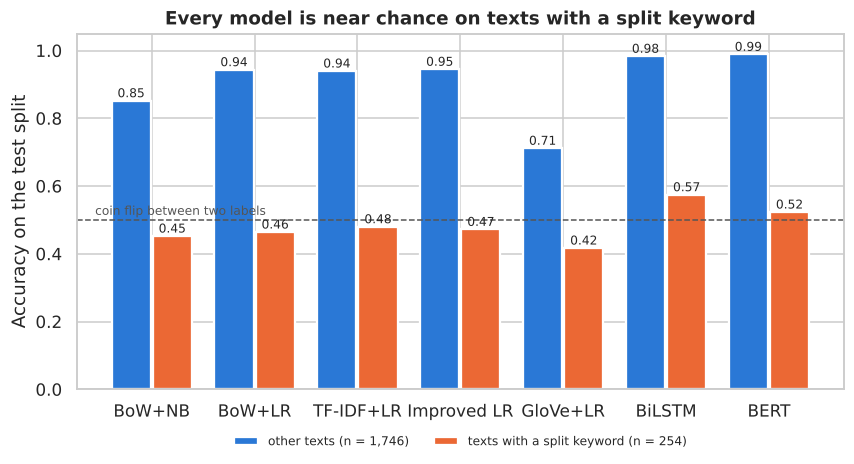

In [12]:
split_word_test = [lexicon.split_word_in(t) for t in X_test]
has_split = np.array([w is not None for w in split_word_test])
train_labels_of = train.groupby("text")["label"].agg(lambda s: set(s)).to_dict()
conflict = np.array([t in train_labels_of and y not in train_labels_of[t] for t, y in zip(X_test, y_test)])

noise_rows = []
for m in LADDER:
    wrong = preds[m] != y_test
    noise_rows.append({
        "model": SHORT[m],
        "accuracy, split-keyword texts": np.mean(~wrong[has_split]),
        "accuracy, other texts": np.mean(~wrong[~has_split]),
        "macro-F1, other texts": macro_f1(y_test[~has_split], preds[m][~has_split]),
        "errors": int(wrong.sum()),
        "errors on split-keyword texts": int((wrong & has_split).sum()),
        "share of errors": (wrong & has_split).sum() / wrong.sum(),
    })
noise = pd.DataFrame(noise_rows).set_index("model")
noise.to_csv(METRICS_DIR / "split_keyword_accuracy_test.csv")
print(f"Test texts with a split keyword: {has_split.sum()} ({has_split.mean():.1%}); "
      f"test texts that occur in training with a different label: {conflict.sum()}")
display(noise.style.format({c: "{:.3f}" for c in noise.columns if c not in ("errors", "errors on split-keyword texts")}))
follows_train = np.mean([ID2LABEL[preds["bert"][i]] in {ID2LABEL[l] for l in train_labels_of[X_test[i]]}
                         for i in np.where(conflict)[0]])
print(f"For {follows_train:.0%} of the conflicting duplicates BERT predicts the label the text has in training.")
print("Conflicting duplicates (gold label in test vs labels in training):")
for i in np.where(conflict)[0]:
    other = ", ".join(ID2LABEL[l] for l in sorted(train_labels_of[X_test[i]]))
    print(f"  [{i}] test: {ID2LABEL[y_test[i]]:<8} train: {other:<17} BERT: {ID2LABEL[preds['bert'][i]]:<8} | {X_test[i][:80]}")

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(LADDER))
ax.bar(x - 0.2, noise["accuracy, other texts"], 0.38, color="#2a78d6", label=f"other texts (n = {(~has_split).sum():,})",
       edgecolor="white", linewidth=1.5)
ax.bar(x + 0.2, noise["accuracy, split-keyword texts"], 0.38, color="#eb6834",
       label=f"texts with a split keyword (n = {has_split.sum()})", edgecolor="white", linewidth=1.5)
for xi, (a, b) in enumerate(zip(noise["accuracy, other texts"], noise["accuracy, split-keyword texts"])):
    ax.text(xi - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8)
    ax.text(xi + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=8)
ax.axhline(0.5, color="#555555", ls="--", lw=1)
ax.text(-0.55, 0.515, "coin flip between two labels", ha="left", fontsize=8, color="#555555")
ax.set_xticks(x, [SHORT[m] for m in LADDER])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy on the test split")
ax.set_title("Every model is near chance on texts with a split keyword")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8, frameon=False)
savefig(fig, "crypt_split_keywords.png")
plt.show()

**Interpretation.** Twenty emotion words are split almost exactly between two classes in the training split: *overwhelmed* (fear 46 / surprise 51), *stressed* (sadness 53 / anger 37), *blessed* (joy 45 / love 38), *agitated* (fear 41 / anger 39) and so on. The pairs are always neighbouring emotions — joy/love, fear/surprise, sadness/anger, sadness/fear — which suggests that these words were listed under two emotions when the labels were assigned. The context does not resolve the split: a classifier that sees each text **without** its keyword is right 52.0% of the time, below the majority baseline of 55.2% (pooled over 1,637 training texts). For these words the label is, as far as the text can tell, random.

This is **label noise**, and it sets a ceiling. 254 test texts (12.7%) contain a split keyword. On them every model is close to a coin flip between two labels (accuracy 0.42–0.57); on the other 1,746 texts BERT is right 98.9% of the time (macro-F1 0.989) and the BiLSTM 98.3%. **121 of BERT's 140 errors (86%) and 108 of the BiLSTM's 137 (79%) fall on split-keyword texts**, against 56% for TF-IDF + LR and 23% for GloVe + LR, whose errors elsewhere still dominate. The better the model, the more of its remaining error is annotation noise. Eleven test texts also occur in the training split with a different label; for 7 of them BERT predicts the training label — it has learned the training annotation, which the test annotation contradicts.

### 4.3 Negation in the annotation

`01_eda` found that texts with a negation cue are harder for every model. Part of the reason lies in the labels themselves. For each training text whose keyword is **reliable**, it is checked whether a negation cue (the `NEGATION_RE` of `src/slices.py`) occurs among the five tokens before the keyword, and whether the gold label equals the keyword's majority label. If annotators had read the negation, "i don t feel happy" would rarely be labelled *joy*.

In [13]:
def keyword_negated(text, keyword, window=5):
    # True if a negation cue occurs within `window` tokens before the keyword.
    tokens = text.split()
    if keyword not in tokens:
        return False
    position = tokens.index(keyword)
    return bool(NEGATION_RE.search(" ".join(tokens[max(0, position - window):position])))


reliable = lexicon.reliable_words
neg_rows = []
for text, label, kw in zip(X_train, labels_train, keywords_train):
    if kw in reliable:
        neg_rows.append({"text": text, "label": label, "keyword": kw, "negated": keyword_negated(text, kw),
                         "label = keyword majority": label == kw_table.at[kw, "majority"]})
neg_frame = pd.DataFrame(neg_rows)
neg_summary = neg_frame.groupby("negated")["label = keyword majority"].agg(["size", "mean"])
neg_summary.index = ["keyword not negated", "keyword negated"]
neg_summary.columns = ["training texts", "label = keyword's majority label"]
display(neg_summary.style.format({"label = keyword's majority label": "{:.3f}"}))
display(neg_frame[neg_frame.negated].sample(8, random_state=SEED)[["text", "keyword", "label"]].style.hide(axis="index"))

,training texts,label = keyword's majority label
keyword not negated,11150,0.964
keyword negated,991,0.942


text,keyword,label
i would accept your gift without feeling mad,mad,anger
i feel louis vuitton took it up to the court and now on for instance ebay you cannot buy fake lv anymore well not on purpose that is,fake,sadness
i didnt feel alarmed moreso a feeling of total welcome,alarmed,fear
im not feeling deprived at all although i do wake up ravenous in the morning,deprived,sadness
i didn t feel too hot from the swim,hot,love
i feel nevertheless not convinced which g is the be all and end all which sprint is creating it away to be,convinced,joy
i simply can t help but feel dissatisfied after reading glancing through each,dissatisfied,anger
i am not in general feeling particularly virtuous this month,virtuous,joy


**Interpretation.** When the keyword is negated ("i didnt feel alarmed", "im not feeling deprived"), the label is still the keyword's usual label in 94.2% of 991 training texts, almost as often as without negation (96.4%). The annotation does not read negation: *i didn t feel too hot* is labelled *love* because *hot* is a love word. A model trained on these labels is rewarded for ignoring negation, so failing a negation test (§6) is partly the correct reproduction of the training labels, not only a weakness of the representation.

### 4.4 A linguistic coding scheme for errors

Each misclassified test text receives one **primary category**. The categories are ordered by linguistic level, from the annotation to pragmatics, and assigned by fixed rules (`src/error_analysis.py`) in the order A1 → B → C → D → E → A2 → F, so that a text with a split keyword is always counted as annotation noise even if it also contains, say, a negation. The rules are approximations: they make the coding reproducible and apply it to all errors of all models; §4.5 checks them against a close reading of individual texts.

,level,category,rule
code,,,
A1,Annotation,Split keyword,"The text contains a split keyword: its training texts are divided between two labels, and the context does not predict which (§4.2)."
A2,Annotation,Gold label contradicts a reliable keyword,"The keyword has one dominant training label, the prediction follows it, the gold label does not, and no negation, modality or competing cue explains the difference."
B,Pragmatics,Implicit emotion,"The text contains no emotion keyword: the emotion must be inferred from the event or situation described (its appraisal), which requires world knowledge."
C,Discourse,Competing emotion cues,"Reliable keywords of two or more classes occur in the text and the model chose a different one than the annotator (mixed emotions, contrast, emotions of other people)."
D,Syntax-semantics,Negation or modality scope,"A negation cue or an irrealis marker (if, hope, would, should, want ...) occurs within 5 tokens before the keyword or the feel verb."
E,Lexicon,Rare or unseen keyword,"The word after feel is not in the keyword lexicon (fewer than 10 training occurrences), so the model must generalise from its form or its context."
F,Other,Other,"A reliable keyword, no competing cue and no scope marker: the model is simply wrong."


code,A1,A2,B,C,D,E,F,total errors
BoW+NB,139,4,42,51,21,26,114,397
BoW+LR,136,7,17,48,3,10,13,234
TF-IDF+LR,132,5,21,43,3,10,23,237
Improved LR,134,5,13,51,4,10,13,230
GloVe+LR,148,7,64,75,48,50,259,651
BiLSTM,108,1,11,10,1,4,2,137
BERT,121,1,8,3,1,5,1,140


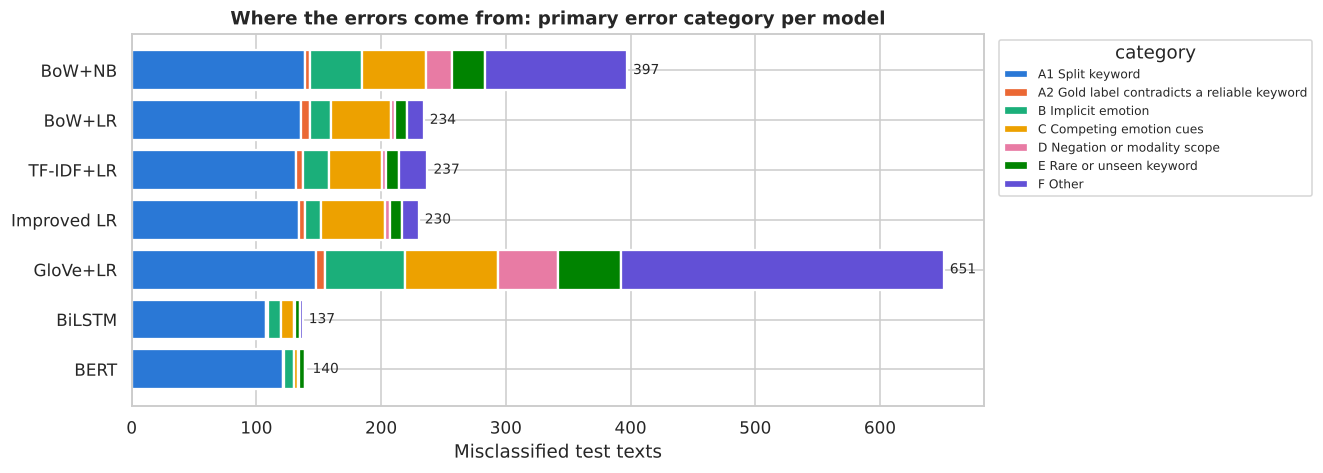

In [14]:
display(ERROR_CATEGORIES.style.set_properties(subset=["rule"], **{"text-align": "left", "white-space": "normal"}))

CATEGORY_COLORS = dict(zip(ERROR_CATEGORIES.index, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                                                   "#008300", "#6250d6"]))
coded = {}
for m in LADDER:
    frame = pred_frames[m]
    coded[m] = frame[~frame["correct"]].join(code_errors(frame[~frame["correct"]], lexicon))
codes_test = pd.concat([c.assign(model=m) for m, c in coded.items()])
codes_test[["model", "idx", "text", "true_label", "pred_label", "code", "category", "level", "keyword",
            "split_word", "scope_marker", "cue_classes"]].to_csv(METRICS_DIR / "error_codes_test.csv", index=False)

counts = pd.DataFrame({SHORT[m]: coded[m]["code"].value_counts() for m in LADDER}).T.reindex(
    columns=ERROR_CATEGORIES.index).fillna(0).astype(int)
counts["total errors"] = counts.sum(axis=1)
display(counts)

fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(LADDER))
y = np.arange(len(LADDER))[::-1]
for code_ in ERROR_CATEGORIES.index:
    values = counts[code_].to_numpy()
    ax.barh(y, values, left=left, color=CATEGORY_COLORS[code_], edgecolor="white", linewidth=1.5,
            label=f"{code_} {ERROR_CATEGORIES.at[code_, 'category']}")
    left += values
for yi, total in zip(y, counts["total errors"]):
    ax.text(total + 5, yi, str(total), va="center", fontsize=9)
ax.set_yticks(y, counts.index)
ax.set_xlabel("Misclassified test texts")
ax.set_title("Where the errors come from: primary error category per model")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, title="category")
savefig(fig, "crypt_error_categories.png")
plt.show()

**Interpretation.** The figure separates the models by *where* their errors come from rather than by how many they make. The number of split-keyword errors (A1, blue) is almost the same for every model (108–148): no representation can learn a coin flip. What changes along the ladder is everything else. Naive Bayes and GloVe + LR also fail on texts with a reliable keyword and no complication (F: 114 and 259 errors), the sparse logistic regressions still fail when **several emotion words compete** (C: 43–51), and the two sequence models have almost nothing left outside A1: BERT has 19 errors in total in categories A2–F, the BiLSTM 29.

The three error types that matter for the best model are, in order of size:

1. **Annotation noise** (A1 + A2: 122 of 140 errors) — inconsistent labels for the same emotion word, conflicting duplicates and labels that contradict the text.
2. **Implicit emotion** (B: 8) — event descriptions without an emotion word, where the emotion must be inferred from world knowledge.
3. **Rare words and composition** (E, C, D: 9) — unseen or rare keywords split into misleading WordPieces, competing cues, and negation or modality.

### 4.5 Annotated error examples

Eighteen misclassified test texts of the best model, chosen to cover every category and every linguistic level. The explanations (`data/handcrafted/error_examples.csv`) were written after reading each text together with the training statistics of its keyword. Two diagnostics are added: the **automatic category** of §4.4, to compare rule and close reading, and **BERT occlusion** — the word whose deletion lowers the probability of BERT's (wrong) prediction the most, a perturbation-based explanation that, unlike attention weights, measures an effect on the output.

In [15]:
examples = pd.read_csv(DATA_DIR / "handcrafted" / "error_examples.csv")
bert_predictor = load_predictor("bert")
example_rows = []
for _, ex in examples.iterrows():
    i = int(ex["idx"])
    assert preds["bert"][i] != y_test[i], f"text {i} is not a BERT error"
    bert_label = ID2LABEL[preds["bert"][i]]
    drops = occlusion(bert_predictor.predict_proba, X_test[i], bert_label)
    auto = coded["bert"].loc[i]
    example_rows.append({
        "idx": i, "text": X_test[i], "gold": ID2LABEL[y_test[i]],
        "BERT": f"{bert_label} ({probas['bert'][i].max():.2f})",
        "TF-IDF+LR": ID2LABEL[preds["tfidf_lr"][i]], "BiLSTM": ID2LABEL[preds["bilstm"][i]],
        "BERT occlusion": f"{drops.index[0]} ({drops.iloc[0]:+.2f})",
        "auto category": f"{auto['code']} {auto['category']}",
        "level": ex["level"], "phenomenon": ex["phenomenon"], "explanation": ex["explanation"],
    })
example_table = pd.DataFrame(example_rows)
example_table.to_csv(METRICS_DIR / "error_examples_test.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(example_table.drop(columns="explanation").style.hide(axis="index")
        .set_properties(subset=["text"], **{"text-align": "left", "white-space": "normal", "min-width": "260px"}))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   5%|▍         | 10/201 [00:00<00:01, 96.27it/s]

Loading weights:  10%|▉         | 20/201 [00:00<00:03, 58.65it/s]

Loading weights:  14%|█▍        | 28/201 [00:00<00:03, 50.71it/s]

Loading weights:  17%|█▋        | 34/201 [00:00<00:03, 44.43it/s]

... (23 outputs left out)

Loading weights:  94%|█████████▎| 188/201 [00:04<00:00, 40.84it/s]

Loading weights:  96%|█████████▌| 193/201 [00:05<00:00, 33.87it/s]

Loading weights: 100%|██████████| 201/201 [00:05<00:00, 39.75it/s]

idx,text,gold,BERT,TF-IDF+LR,BiLSTM,BERT occlusion,auto category,level,phenomenon
188,i feel kinda weird when andrea tries to talk to me about chris,fear,surprise (0.77),fear,surprise,weird (+0.74),A1 Split keyword,Annotation,Split keyword
336,i do feel stressed,sadness,anger (0.72),sadness,anger,stressed (+0.71),A1 Split keyword,Annotation,Split keyword without context
546,i feel so blessed to be able to share it with you all,joy,love (0.88),joy,joy,blessed (+0.88),A1 Split keyword,Annotation,Split keyword (joy / love)
103,i feel agitated with myself that i did not foresee her frustrations earlier leading to the ending of our relationship,fear,anger (0.86),anger,anger,agitated (+0.11),A1 Split keyword,Annotation / syntax-semantics,Split keyword; target of the emotion
1613,i feel very cheated since i am supporting the family and doing all the other stuff while he spends hours a day gaming,joy,love (0.87),joy,love,supporting (+0.87),A1 Split keyword,Annotation,"Label assigned from a lexicon word, not from the stated emotion"
86,i feel like i am in paradise kissing those sweet lips make me feel like i dive into a magical world of love,joy,love (0.71),joy,joy,sweet (+0.71),A1 Split keyword,Annotation / lexical semantics,Joy-love boundary
1928,i feel inside cause life is like a game sometimes but then you came around me the walls just disappeared nothing to surround me and keep me from my fears im unprotected see how ive opened up youve made me trust,fear,sadness (1.00),sadness,sadness,disappeared (+0.98),E Rare or unseen keyword,Annotation,Near-duplicate texts with different labels
1725,i feel like it add a little bit more shield from the cold and the fabric is great for wicking away sweat,anger,joy (0.54),joy,anger,great (+0.54),F Other,Lexical semantics (polysemy),Keyword in a non-emotional sense
150,im feeling rather angsty and listless,sadness,anger (0.99),sadness,sadness,angsty (+0.99),E Rare or unseen keyword,Morphology (WordPiece),Rare word split into misleading subwords
426,i feel unprotected a class post count link href http reprogramming in process,sadness,fear (1.00),fear,fear,unprotected (+1.00),E Rare or unseen keyword,Annotation / data quality,Scraping residue and an inconsistent label


The explanations, one per example:

In [16]:
for row in example_rows:
    display(Markdown(f"**[{row['idx']}] {row['phenomenon']}** — *{row['text']}*  \n"
                     f"gold **{row['gold']}**, BERT **{row['BERT']}**, TF-IDF + LR **{row['TF-IDF+LR']}**, "
                     f"BiLSTM **{row['BiLSTM']}**; occlusion: {row['BERT occlusion']}  \n{row['explanation']}"))

**[188] Split keyword** — *i feel kinda weird when andrea tries to talk to me about chris*  
gold **fear**, BERT **surprise (0.77)**, TF-IDF + LR **fear**, BiLSTM **surprise**; occlusion: weird (+0.74)  
weird is labelled fear 43 times and surprise 34 times in the training split. The context (an awkward conversation about another person) fits either reading, so neither label can be derived from the text: the gold label is effectively a coin flip between the two classes the annotation assigns to this word.

**[336] Split keyword without context** — *i do feel stressed*  
gold **sadness**, BERT **anger (0.72)**, TF-IDF + LR **sadness**, BiLSTM **anger**; occlusion: stressed (+0.71)  
Three words. stressed is labelled sadness 53 times and anger 37 times in training, and there is no context to disambiguate. Emphatic do adds intensity, not a direction. The best possible strategy is to guess the majority label, which is what TF-IDF + LR does; BERT and the BiLSTM guess the minority label.

**[546] Split keyword (joy / love)** — *i feel so blessed to be able to share it with you all*  
gold **joy**, BERT **love (0.88)**, TF-IDF + LR **joy**, BiLSTM **joy**; occlusion: blessed (+0.88)  
blessed is labelled joy 45 times and love 38 times. Gratitude towards readers ('share it with you all') lies on the boundary between the two classes; the label set does not say where gratitude belongs, and the annotation treats it inconsistently.

**[103] Split keyword; target of the emotion** — *i feel agitated with myself that i did not foresee her frustrations earlier leading to the ending of our relationship*  
gold **fear**, BERT **anger (0.86)**, TF-IDF + LR **anger**, BiLSTM **anger**; occlusion: agitated (+0.11)  
agitated is divided between fear (41) and anger (39) in training. The prepositional phrase with myself names the target of the emotion, and self-blame for not foreseeing a break-up is anger directed at oneself. The models' anger is linguistically better motivated than the gold fear.

**[1613] Label assigned from a lexicon word, not from the stated emotion** — *i feel very cheated since i am supporting the family and doing all the other stuff while he spends hours a day gaming*  
gold **joy**, BERT **love (0.87)**, TF-IDF + LR **joy**, BiLSTM **love**; occlusion: supporting (+0.87)  
The emotion is stated explicitly (i feel very cheated), and cheated is a negative word (sadness 4, anger 4 in training). The gold label joy cannot come from it; it matches supporting (joy 48 / love 46 in training) later in the sentence. Occlusion confirms that BERT also relies on supporting. This is direct evidence that labels were assigned from an emotion word in the text rather than from the meaning of the sentence.

**[86] Joy-love boundary** — *i feel like i am in paradise kissing those sweet lips make me feel like i dive into a magical world of love*  
gold **joy**, BERT **love (0.71)**, TF-IDF + LR **joy**, BiLSTM **joy**; occlusion: sweet (+0.71)  
The sentence ends with 'a magical world of love', and kissing and sweet lips describe romantic affection. The gold joy is supported only by paradise. BERT's love is the more plausible reading: for romantic happiness the two classes overlap.

... (8 outputs left out)

**[611] Competing emotion cues in a long text** — *i couldnt help feeling for him and this awful predicament he lives with on a daily and nightly basis and i was just so glad that once bel started to see the light he stuck it out and stood by daniel whilst no one else did including his family who im afraid i got really disgusted with*  
gold **sadness**, BERT **joy (0.51)**, TF-IDF + LR **sadness**, BiLSTM **sadness**; occlusion: glad (+0.51)  
The text contains cues of four classes: feeling for him (sympathy), awful predicament (sadness), so glad (joy) and disgusted (anger). The annotator chose sadness, BERT joy with 0.51 confidence (almost a tie). A single-label scheme forces one emotion where the discourse expresses a sequence of emotions.

**[789] Negation ignored by the annotation** — *i did not feel any passionate joy*  
gold **joy**, BERT **love (0.87)**, TF-IDF + LR **joy**, BiLSTM **joy**; occlusion: passionate (+0.87)  
The writer reports the absence of joy (did not feel any passionate joy), yet the gold label is joy: in training, texts with a negated emotion word almost always carry that word's label (§4.3). BERT predicts love from passionate (joy 35 / love 48). Neither the annotation nor the model takes the scope of not into account.

**[1977] Ironic positive word** — *i spent last night on the couch feeling like i was suffering from hypothermia while the house remained at a balmy*  
gold **sadness**, BERT **joy (0.66)**, TF-IDF + LR **sadness**, BiLSTM **sadness**; occlusion: balmy (+0.66)  
The house 'remained at a balmy' (the temperature that followed has been cut off) after the writer felt like 'suffering from hypothermia': balmy is ironic. Occlusion shows that BERT's joy depends on balmy (drop 0.66); the word-level models follow suffering and are correct.

**[1382] Mock-solemn hyperbole with an unsupported label** — *i cannot even begin to express in words the depth of sorrow that i feel having not posted any of my ludicrous rants over the passed days*  
gold **surprise**, BERT **sadness (0.99)**, TF-IDF + LR **sadness**, BiLSTM **surprise**; occlusion: ludicrous (+0.95)  
'The depth of sorrow' is a humorous exaggeration about not having posted 'ludicrous rants'. BERT and TF-IDF + LR read sorrow literally (sadness, BERT 0.99); the BiLSTM predicts surprise. The gold surprise is not supported by any emotion word in the text (ludicrous is labelled sadness 6 times and surprise 3 times in training).

**Interpretation.** Close reading confirms the rule-based coding for most examples and refines it for a few. The automatic rules put 1928 and 426 under "rare keyword" and 1725 under "other", but reading them shows annotation problems: a lyric labelled twice with different emotions, a word labelled *fear* in training but *sadness* here, and *cold* in the sense of temperature labelled *anger* because the word is an anger keyword. Example 1613 is the clearest evidence for the labelling mechanism: the writer states *i feel very cheated*, yet the gold label (*joy*) is the label of *supporting*, a word in the subordinate clause.

The genuine model errors are linguistically interesting. **Morphology:** *angsty* is split by WordPiece into *ang* + *##sty* and pushes BERT to *anger* with 0.99 confidence. **Experiencer:** in *make the person happy* the emotion word describes someone else. **Reported speech:** *the most hated man ... said assessor steve helm* is a quotation. **Irony:** *balmy* after *hypothermia*. **Appraisal:** *flunked for the second time* names no emotion. These phenomena are rare in this dataset, which is why they hardly affect the scores — and exactly why the behavioural tests of §6 are needed to measure them.

## 5. Where TF-IDF + LR and BERT disagree

The baseline and the best model share the same training data and the same label set; they differ in the representation. Texts on which exactly one of them is right show what the contextual representation adds — and what it costs.

### 5.1 Agreement table

In [17]:
lr_ok, bert_ok = preds["tfidf_lr"] == y_test, preds["bert"] == y_test
agreement = pd.DataFrame([[np.sum(lr_ok & bert_ok), np.sum(lr_ok & ~bert_ok)],
                          [np.sum(~lr_ok & bert_ok), np.sum(~lr_ok & ~bert_ok)]],
                         index=["TF-IDF+LR correct", "TF-IDF+LR wrong"], columns=["BERT correct", "BERT wrong"])
display(agreement)
same_wrong = np.sum(~lr_ok & ~bert_ok & (preds["tfidf_lr"] == preds["bert"]))
print(f"Same label: {np.mean(preds['tfidf_lr'] == preds['bert']):.1%} of texts | both wrong: {np.sum(~lr_ok & ~bert_ok)} "
      f"({same_wrong} with the same wrong label) | BERT only correct: {np.sum(~lr_ok & bert_ok)} | "
      f"TF-IDF+LR only correct: {np.sum(lr_ok & ~bert_ok)}")

,BERT correct,BERT wrong
TF-IDF+LR correct,1697,66
TF-IDF+LR wrong,163,74


Same label: 88.0% of texts | both wrong: 74 (64 with the same wrong label) | BERT only correct: 163 | TF-IDF+LR only correct: 66


### 5.2 Which kinds of text profit from BERT?

The disagreements are broken down by the slices used throughout the project (`src/slices.py`): the gold class, the use of the *feel* template, a negation cue, text length (quartiles of the training split), a word never seen in training, and — new in this notebook — a split keyword. For each slice, *BERT only* is the share of texts that only BERT classifies correctly and *LR only* the share that only TF-IDF + LR classifies correctly; their difference is the net gain of BERT on that slice.

slice,level,texts,TF-IDF+LR accuracy,BERT accuracy,BERT only,LR only,net gain of BERT
gold class,sadness,581,0.923,0.943,0.045,0.024,0.021
gold class,joy,695,0.935,0.917,0.026,0.045,-0.019
gold class,love,159,0.730,0.969,0.264,0.025,0.239
gold class,anger,275,0.862,0.985,0.124,0.000,0.124
gold class,fear,224,0.812,0.835,0.098,0.076,0.022
gold class,surprise,66,0.636,0.955,0.318,0.000,0.318
feel template,starts with 'i feel',655,0.901,0.937,0.067,0.031,0.037
feel template,feel elsewhere,1306,0.883,0.930,0.082,0.034,0.047
feel template,no form of feel,39,0.513,0.795,0.308,0.026,0.282
negation cue,without negation cue,1430,0.887,0.936,0.080,0.031,0.048


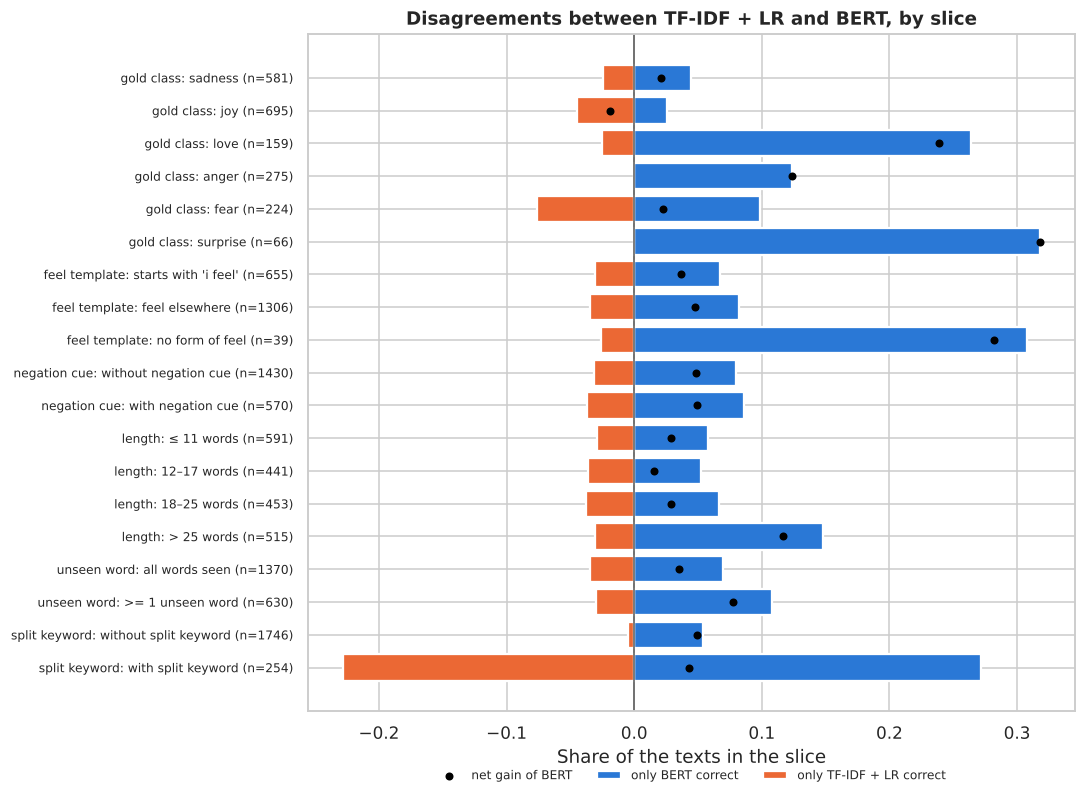

In [18]:
lengths = np.array([len(t.split()) for t in X_test])
quartiles = np.percentile([len(t.split()) for t in X_train], [25, 50, 75])
length_bin = np.digitize(lengths, quartiles, right=True)
length_names = [f"≤ {int(quartiles[0])} words", f"{int(quartiles[0]) + 1}–{int(quartiles[1])} words",
                f"{int(quartiles[1]) + 1}–{int(quartiles[2])} words", f"> {int(quartiles[2])} words"]
train_vocab = training_vocabulary(X_train)
slice_order = {"gold class": LABELS, "feel template": TEMPLATE_LEVELS,
               "negation cue": ["without negation cue", "with negation cue"], "length": length_names,
               "unseen word": ["all words seen", ">= 1 unseen word"],
               "split keyword": ["without split keyword", "with split keyword"]}
slices = {
    "gold class": gold_test,
    "feel template": template_slice(X_test),
    "negation cue": np.where(has_negation(X_test), "with negation cue", "without negation cue"),
    "length": np.array([length_names[b] for b in length_bin], dtype=object),
    "unseen word": np.where(unseen_word_mask(X_test, train_vocab), ">= 1 unseen word", "all words seen"),
    "split keyword": np.where(has_split, "with split keyword", "without split keyword"),
}
slice_rows = []
for family, levels in slices.items():
    for level in slice_order[family]:
        mask = levels == level
        n = int(mask.sum())
        slice_rows.append({"slice": family, "level": level, "texts": n,
                           "TF-IDF+LR accuracy": lr_ok[mask].mean(), "BERT accuracy": bert_ok[mask].mean(),
                           "BERT only": np.mean(~lr_ok[mask] & bert_ok[mask]),
                           "LR only": np.mean(lr_ok[mask] & ~bert_ok[mask])})
disagreement = pd.DataFrame(slice_rows)
disagreement["net gain of BERT"] = disagreement["BERT only"] - disagreement["LR only"]
disagreement.to_csv(METRICS_DIR / "disagreement_slices_tfidf_bert.csv", index=False)
display(disagreement.style.format({c: "{:.3f}" for c in disagreement.columns[3:]}).hide(axis="index")
        .bar(subset=["net gain of BERT"], align="zero", color=["#eb6834", "#2a78d6"]))

fig, ax = plt.subplots(figsize=(9, 8))
plot = disagreement.iloc[::-1].reset_index(drop=True)
y = np.arange(len(plot))
ax.barh(y, plot["BERT only"], color="#2a78d6", edgecolor="white", linewidth=1.5, label="only BERT correct")
ax.barh(y, -plot["LR only"], color="#eb6834", edgecolor="white", linewidth=1.5, label="only TF-IDF + LR correct")
ax.scatter(plot["net gain of BERT"], y, color="black", s=18, zorder=3, label="net gain of BERT")
ax.axvline(0, color="#555555", lw=1)
ax.set_yticks(y, [f"{s}: {l} (n={n})" for s, l, n in zip(plot["slice"], plot["level"], plot["texts"])], fontsize=8)
ax.set_xlabel("Share of the texts in the slice")
ax.set_title("Disagreements between TF-IDF + LR and BERT, by slice")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=8, frameon=False)
savefig(fig, "crypt_disagreement_slices.png")
plt.show()

**Interpretation.** The two models agree on 88% of the texts. BERT's net gain is concentrated where a bag of words lacks information: the minority classes *surprise* (+0.318) and *love* (+0.239), the few texts with **no form of feel** (+0.282, n = 39), **long texts** of more than 25 words (+0.117, against +0.016 to +0.029 for shorter texts) and texts with a word never seen in training (+0.078 vs +0.035). A long text contains more words that are not the keyword, so the sum over all word weights of a linear model is diluted; a contextual encoder can attend to the one relevant word wherever it occurs. *Joy* is the only class where BERT loses (−0.019), the counterpart of the joy → love shift of §3.

Two results run against a common expectation. BERT gains no more on texts with a **negation cue** than on texts without (+0.049 vs +0.048): self-attention can represent the scope of *not*, but the labels do not reward it (§4.3). And on texts with a **split keyword** both models are right only on different halves (27.2% only BERT, 22.8% only LR, net +0.043): they are flipping different coins.

### 5.3 What misleads the linear model?

For a softmax regression the decision between the predicted class $k$ and the gold class $g$ depends on the score difference $(\mathbf{w}_k - \mathbf{w}_g)^\top \mathbf{x} + (b_k - b_g)$, so every word $j$ contributes $x_j\,(w_{k,j} - w_{g,j})$ (Lecture 5). For each text that only BERT gets right, the word with the largest contribution towards TF-IDF + LR's wrong answer is identified, and compared with the word BERT depends on most for its correct answer (occlusion: the word whose deletion lowers P(gold) the most). Each word is classified as the text's **keyword** (the word after *feel*), **another keyword** of the lexicon (an emotion word in a different position), or **a word outside the lexicon** (function words, *feel* itself, evaluative words such as *good*).

In [19]:
lr_pipeline = joblib.load(CLASSICAL_DIR / "tfidf_lr.joblib")
bert_only = np.where(~lr_ok & bert_ok)[0]
lr_only = np.where(lr_ok & ~bert_ok)[0]


def word_role(word, text):
    # Role of a word in a text: its emotion keyword, another emotion word of the lexicon, or a non-emotion word.
    keyword = feel_complement(text) if feel_complement(text) in kw_table.index else lexicon.keyword(text)
    if word.split("@")[0] == keyword:
        return "the keyword"
    return "another lexicon keyword" if word.split("@")[0] in kw_table.index else "a word outside the lexicon"


driver_rows = []
for i in bert_only:
    lr_label, gold = ID2LABEL[preds["tfidf_lr"][i]], ID2LABEL[y_test[i]]
    contrib = lr_contributions(lr_pipeline, X_test[i], lr_label, gold)
    drops = occlusion(bert_predictor.predict_proba, X_test[i], gold)
    driver_rows.append({"idx": i, "gold": gold, "TF-IDF+LR": lr_label,
                        "LR top word": contrib.index[0], "LR top word is": word_role(contrib.index[0], X_test[i]),
                        "BERT top word": drops.index[0], "BERT top word is": word_role(drops.index[0], X_test[i])})
drivers = pd.DataFrame(driver_rows)
roles = ["the keyword", "another lexicon keyword", "a word outside the lexicon"]
role_table = pd.DataFrame({
    "TF-IDF+LR: word pushing most towards its wrong label": drivers["LR top word is"].value_counts(normalize=True),
    "BERT: word whose deletion lowers P(gold) most": drivers["BERT top word is"].value_counts(normalize=True),
}).reindex(roles).fillna(0)
print(f"Texts that only BERT classifies correctly: {len(drivers)}")
display(role_table.style.format("{:.1%}"))
print("Most frequent words that pull TF-IDF + LR away from the gold label (not the keyword):")
display(drivers[drivers["LR top word is"] != "the keyword"].groupby("LR top word")
        .agg(texts=("idx", "size"), towards=("TF-IDF+LR", lambda s: ", ".join(sorted(set(s)))))
        .sort_values("texts", ascending=False).head(12).T)

Texts that only BERT classifies correctly: 163


,TF-IDF+LR: word pushing most towards its wrong label,BERT: word whose deletion lowers P(gold) most
the keyword,8.0%,74.8%
another lexicon keyword,24.5%,4.3%
a word outside the lexicon,67.5%,20.9%


Most frequent words that pull TF-IDF + LR away from the gold label (not the keyword):


LR top word,feel,good,special,can,away,better,surprised,unhappy,peaceful,about,before,bit
texts,11,5,2,2,2,2,2,2,2,1,1,1
towards,"joy, sadness",joy,joy,joy,joy,joy,surprise,sadness,joy,fear,fear,sadness


Eight examples (the texts with the most confident wrong TF-IDF + LR prediction among those without a split keyword and with at most 25 words). The last column shows which word BERT relies on for its correct answer: the word whose deletion lowers P(gold) the most.

In [20]:
candidates = [i for i in bert_only if not has_split[i] and len(X_test[i].split()) <= 25]
candidates = sorted(candidates, key=lambda i: -probas["tfidf_lr"][i].max())[:8]
lr_examples = []
for i in candidates:
    lr_label, gold = ID2LABEL[preds["tfidf_lr"][i]], ID2LABEL[y_test[i]]
    contrib = lr_contributions(lr_pipeline, X_test[i], lr_label, gold)
    drops = occlusion(bert_predictor.predict_proba, X_test[i], gold)
    lr_examples.append({"idx": i, "text": X_test[i], "gold = BERT": gold,
                        "TF-IDF+LR": f"{lr_label} ({probas['tfidf_lr'][i].max():.2f})",
                        "LR: words pushing to its answer": ", ".join(f"{w} {v:+.2f}" for w, v in contrib.head(3).items()),
                        "BERT: occlusion of P(gold)": ", ".join(f"{w} {v:+.2f}" for w, v in drops.head(2).items())})
lr_examples = pd.DataFrame(lr_examples)
display(lr_examples.style.hide(axis="index").set_properties(subset=["text"], **{"text-align": "left", "white-space": "normal"}))

idx,text,gold = BERT,TF-IDF+LR,LR: words pushing to its answer,BERT: occlusion of P(gold)
242,i see you on the pitchers mound at our little league diamond i feel so anxious for you because it looks so isolated over there,fear,sadness (0.98),"isolated +3.35, league +0.84, looks +0.63","anxious +1.00, feel +0.87"
877,i feel respected and secure where i can journey toward loving and be loved in return,joy,love (0.97),"loving +5.20, loved +3.35, journey +1.39","feel +0.58, respected +0.20"
796,im much more peaceful and happy when the house is clean the food is good and my kids arent feeling needy,sadness,joy (0.94),"peaceful +3.42, happy +1.59, good +1.23","needy +1.00, feeling +0.08"
630,i have made about sex i feel that women enjoy sex when their body and emotions are admired and respected,love,joy (0.88),"respected +2.79, sex +0.68, feel +0.49","admired +0.95, women -0.01"
867,i was truly surprised and feel quite honored,joy,surprise (0.86),"surprised +10.60, quite +0.64, was +0.29","honored +1.00, feel +1.00"
1188,i felt confused me sometimes that makes me feel useless,sadness,fear (0.85),"confused +5.53, felt +1.37, sometimes +0.39","useless +1.00, feel +0.27"
790,i have nostalgic feelings i have met wonderful people online and the online internet is for me like my second life,joy,love (0.85),"nostalgic +4.95, online +0.97, second +0.25","wonderful +1.00, feelings +0.96"
1255,im not constantly horny or always feeling playful,joy,love (0.81),"horny +8.71, always +0.74, constantly +0.43","playful +1.00, feeling +1.00"


**Interpretation.** The two models rely on different words. On the 163 texts that only BERT classifies correctly, the word BERT depends on most is the **keyword** in 74.8% of the texts. The word that pushes TF-IDF + LR most towards its wrong answer is the keyword in only 8.0%; in 24.5% it is another emotion word, in 67.5% a word outside the lexicon — the most frequent being *feel* itself, whose TF-IDF weight acts as a proxy for text length (Step 2), and evaluative words such as *good*.

The examples show the mechanism. In *i feel so anxious for you because it looks so isolated over there*, the linear model adds the weight of *isolated* (+3.35 towards sadness) to the evidence of *anxious*, although *isolated* describes the place, not the writer; BERT's decision rests on *anxious*. In *i feel respected and secure where i can journey toward loving and be loved*, *loving* and *loved* outweigh *respected*. A bag of words treats every emotion word as a vote, independent of its syntactic role; the contextual model identifies the word that is the complement of *feel* — the word the annotation was based on.

### 5.4 And where BERT loses

The texts that only TF-IDF + LR classifies correctly, coded with the scheme of §4.4.

In [21]:
lr_only_codes = coded["bert"].loc[lr_only, "code"].value_counts().reindex(ERROR_CATEGORIES.index).fillna(0).astype(int)
display(lr_only_codes.rename("texts only TF-IDF+LR gets right").to_frame().T)
show = pd.DataFrame({"idx": lr_only, "text": [X_test[i] for i in lr_only], "gold = TF-IDF+LR": gold_test[lr_only],
                     "BERT": [f"{ID2LABEL[preds['bert'][i]]} ({probas['bert'][i].max():.2f})" for i in lr_only],
                     "category": coded["bert"].loc[lr_only, "code"].to_numpy()})
display(show[show["category"] != "A1"].head(8).style.hide(axis="index")
        .set_properties(subset=["text"], **{"text-align": "left", "white-space": "normal"}))

code,A1,A2,B,C,D,E,F
texts only TF-IDF+LR gets right,58,1,4,1,0,2,0


idx,text,gold = TF-IDF+LR,BERT,category
150,im feeling rather angsty and listless,sadness,anger (0.99),E
468,i cant help feeling this way,sadness,joy (0.63),B
591,i feel inside this life is like a game sometimes then you came around me the walls just dissapeared nothing to surround me keep me from my fears im unprotected see how ive opened up youve made me trust coz ive never felt like this before im naked around you does it show,sadness,joy (0.55),E
611,i couldnt help feeling for him and this awful predicament he lives with on a daily and nightly basis and i was just so glad that once bel started to see the light he stuck it out and stood by daniel whilst no one else did including his family who im afraid i got really disgusted with,sadness,joy (0.51),C
756,getting sent on a company expense trip to another state to work for a week at that plan,joy,anger (0.85),B
845,i did feel rather like a celebrity and widget stood and let herself be admired while she drank orange squash from my cup,joy,love (0.96),B
1195,i remain hopeful that the feeling i have is actually excitement a long missed friend,sadness,joy (0.78),A2
1977,i spent last night on the couch feeling like i was suffering from hypothermia while the house remained at a balmy,sadness,joy (0.66),B


**Interpretation.** 58 of the 66 texts that only TF-IDF + LR gets right (88%) contain a split keyword: BERT's losses are almost entirely coin flips that happen to land differently. Among the few others are the examples of §4.5 where BERT's broader reading hurts: the WordPiece split of *angsty*, the ironic *balmy*, and long texts in which BERT follows a vivid secondary cue (*so glad*) rather than the clause the annotator chose.

## 6. Behavioural tests

Held-out accuracy measures how well a model reproduces the annotation of texts like the training texts. **Behavioural testing** (CheckList; Ribeiro et al., 2020) asks instead whether a model handles specific linguistic capabilities, with small hand-written test sets. The suite in `data/handcrafted/behavioural_tests.csv` has 60 sentences written in the style of the dataset (lower case, no punctuation, contractions as *don t*):

| Capability | Sentences | What is tested | Test types |
|---|---|---|---|
| Negation | 20 | 7 pairs of an emotion statement and its negation (*i feel happy today* / *i don t feel happy today*); 6 sentences whose negation word does **not** reverse the emotion (*i can t stop smiling*) | MFT; DIR: negation must lower P(affirmed emotion) by at least 0.10 |
| Sarcasm | 12 | positive words expressing a negative attitude (*i feel so blessed to be stuck at work on christmas eve*); anger or sadness accepted | MFT |
| Intensity | 18 | 6 groups: downtoner / no modifier / intensifier (*a little sad* / *sad* / *incredibly sad*) | MFT; INV: same label in the group; DIR: the intensifier must not lower P(emotion) below the downtoner |
| Mixed emotions | 10 | two emotions in one sentence (*excited but also terrified*); either label accepted | MFT; both emotions among the two most probable classes |

**MFT** (minimum functionality test) checks the label, **INV** (invariance) checks that a label-preserving change leaves the prediction unchanged, **DIR** (directional expectation) checks that a change moves a probability in the expected direction. The expected labels of negated sentences follow the **meaning** of the sentence (*i don t feel happy* → sadness), not the annotation convention of §4.3; §6.4 compares the two.

In [22]:
suite = load_suite()
display(suite.groupby(["capability", "variant"], sort=False).size().rename("sentences").to_frame().T)
display(suite.groupby("capability", sort=False).head(2)[["test_id", "capability", "variant", "text", "expected"]]
        .assign(expected=lambda d: d["expected"].str.join(" | ")).style.hide(axis="index"))

capability    negation                                  sarcasm intensity  \
variant    affirmative negated negation, emotion kept sarcastic downtoned   
sentences            7       7                      6        12         6   

capability                          mixed  
variant    plain intensified two emotions  
sentences      6           6           10

test_id,capability,variant,text,expected
N01a,negation,affirmative,i feel happy today,joy
N01b,negation,negated,i don t feel happy today,sadness
S01,sarcasm,sarcastic,oh great another monday i just love being stuck in traffic for two hours,anger | sadness
S02,sarcasm,sarcastic,thanks a lot for ruining my birthday i feel so loved,anger | sadness
I01a,intensity,downtoned,i feel a little sad today,sadness
I01b,intensity,plain,i feel sad today,sadness
M01,mixed,two emotions,i am excited but also terrified about moving abroad next month,joy | fear
M02,mixed,two emotions,i feel happy for her but also sad that she is leaving,joy | sadness


### 6.1 Predictions of every model

All seven trained models are loaded through `src/predictors.py` and return their raw softmax probabilities. The LLM (few-shot prompt of Step 6) classifies the 60 sentences through the DeepSeek API; its answers are cached in `results/llm/cache/`, so the notebook re-runs without new requests. Its probabilities are degenerate at temperature 0 (Step 6), so the LLM takes part only in the label-based tests (MFT and INV).

In [23]:
texts_suite = suite["text"].tolist()
items, groups, skipped = [], [], {}
for m in LADDER:
    try:
        predictor = bert_predictor if m == "bert" else load_predictor(m)
    except FileNotFoundError as exc:
        skipped[m] = str(exc)
        continue
    proba_suite = predictor.predict_proba(texts_suite)
    scored = score_items(suite, proba_suite.argmax(axis=1), proba_suite, m)
    items.append(scored)
    groups.append(group_tests(scored))

llm_prompt = load_prompt(LLM_DIR / "prompt_llm.json")
client = DeepSeekClassifier()
try:
    llm_frame = client.run(llm_prompt, texts_suite, list(range(len(suite))), run_name=f"behavioural__{llm_prompt.prompt_id}")
    scored = score_items(suite, llm_frame["pred"].to_numpy(), None, "llm")
    scored["llm_status"] = llm_frame["status"].to_numpy()
    items.append(scored)
    groups.append(group_tests(scored))
except RuntimeError as exc:  # no API key and no cached answers
    skipped["llm"] = str(exc)

items = pd.concat(items, ignore_index=True)
groups = pd.concat(groups, ignore_index=True)
models_run = [m for m in LADDER + ["llm"] if m in set(items["model"])]
items.to_csv(METRICS_DIR / "behavioural_predictions.csv", index=False)
groups.to_csv(METRICS_DIR / "behavioural_group_tests.csv", index=False)
print("models tested: " + ", ".join(SHORT[m] for m in models_run))
for m, reason in skipped.items():
    print(f"skipped {SHORT[m]}: {reason}")

models tested: BoW+NB, BoW+LR, TF-IDF+LR, Improved LR, GloVe+LR, BiLSTM, BERT, LLM (few-shot)


### 6.2 Results

Pass rates per capability (MFT) and per group test. Each cell is the share of passed tests; the number of tests is given in the row label. With 6–20 tests per row, one test changes a rate by 5–17 percentage points, so differences between models within a row are descriptive.

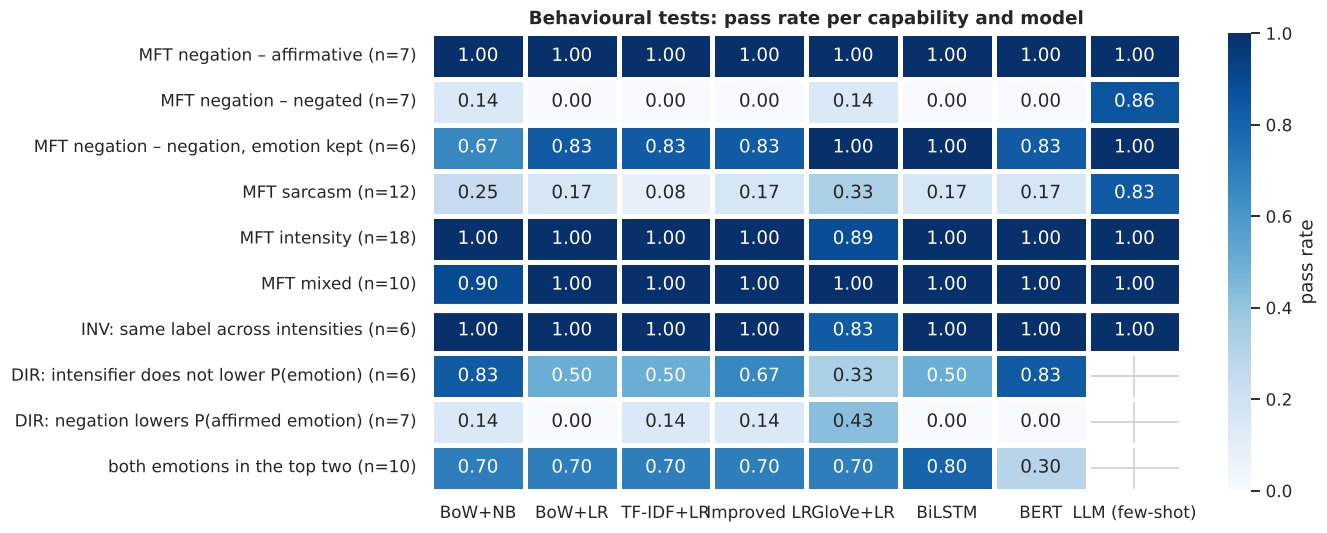

,MFT passed,pass rate,95% Wilson CI,pass rate without the mixed sentences
model,,,,
BoW+NB,42 / 60,0.700,"[0.57, 0.80]",0.660
BoW+LR,42 / 60,0.700,"[0.57, 0.80]",0.640
TF-IDF+LR,41 / 60,0.683,"[0.56, 0.79]",0.620
Improved LR,42 / 60,0.700,"[0.57, 0.80]",0.640
GloVe+LR,44 / 60,0.733,"[0.61, 0.83]",0.680
BiLSTM,43 / 60,0.717,"[0.59, 0.81]",0.660
BERT,42 / 60,0.700,"[0.57, 0.80]",0.640
LLM (few-shot),57 / 60,0.950,"[0.86, 0.98]",0.940


variant,downtoned,plain,intensified
model,,,
BoW+NB,0.629,0.672,0.690
BoW+LR,0.876,0.909,0.874
TF-IDF+LR,0.912,0.974,0.918
Improved LR,0.858,0.920,0.866
GloVe+LR,0.845,0.947,0.855
BiLSTM,1.000,1.000,1.000
BERT,0.999,0.999,0.999


**LLM (few-shot).** MFT pass rates: negation 0.95, sarcasm 0.83, intensity 1.00, mixed 1.00; negated sentences 0.86; answer status: valid 60.

In [24]:
def pass_table(frame, key, value):
    table = frame.pivot_table(index=key, columns="model", values=value, aggfunc="mean").reindex(columns=models_run)
    sizes = frame[frame["model"] == models_run[0]].groupby(key).size()
    table.index = [f"{k} (n={sizes[k]})" for k in table.index]
    return table


mft = items.assign(row=lambda d: np.where(d["capability"] == "negation", "negation: " + d["variant"],
                                          "MFT " + d["capability"]))
mft_table = pass_table(mft, "row", "mft_pass")
order = ["negation: affirmative", "negation: negated", "negation: negation, emotion kept", "MFT sarcasm",
         "MFT intensity", "MFT mixed"]
mft_table = mft_table.loc[[next(r for r in mft_table.index if r.startswith(o + " (")) for o in order]]
mft_table.index = [r.replace("negation: ", "MFT negation – ") for r in mft_table.index]
group_table = pass_table(groups.dropna(subset=["pass"]).assign(**{"pass": lambda d: d["pass"].astype(float)}),
                         "test", "pass")
group_order = ["INV: same label across intensities", "DIR: intensifier does not lower P(emotion)",
               "DIR: negation lowers P(affirmed emotion)", "both emotions in the top two"]
group_table = group_table.loc[[next(r for r in group_table.index if r.startswith(o + " (")) for o in group_order]]
results_table = pd.concat([mft_table, group_table])
results_table.columns = [SHORT[m] for m in results_table.columns]
results_table.to_csv(METRICS_DIR / "behavioural_summary.csv")

fig, ax = plt.subplots(figsize=(11, 5.4))
sns.heatmap(results_table, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "pass rate"}, ax=ax)
ax.axhline(len(mft_table), color="white", lw=6)
ax.set_title("Behavioural tests: pass rate per capability and model")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
savefig(fig, "crypt_behavioural_tests.png")
plt.show()

overall = []
for m in models_run:
    passed = items.loc[items["model"] == m, "mft_pass"]
    low, high = wilson_interval(int(passed.sum()), len(passed))
    no_mixed = items.loc[(items["model"] == m) & (items["capability"] != "mixed"), "mft_pass"]
    overall.append({"model": SHORT[m], "MFT passed": f"{int(passed.sum())} / {len(passed)}",
                    "pass rate": passed.mean(), "95% Wilson CI": f"[{low:.2f}, {high:.2f}]",
                    "pass rate without the mixed sentences": no_mixed.mean()})
display(pd.DataFrame(overall).set_index("model").style.format({"pass rate": "{:.3f}",
                                                                "pass rate without the mixed sentences": "{:.3f}"}))

# Degree modifiers: mean probability of the expected emotion per intensity variant (models with probabilities).
intensity = items[(items["capability"] == "intensity") & items["p_sadness"].notna()].copy()
intensity["P(emotion)"] = [row[f"p_{row['expected']}"] for _, row in intensity.iterrows()]
display(intensity.pivot_table(index="model", columns="variant", values="P(emotion)")
        .reindex(index=[m for m in models_run if m != "llm"], columns=["downtoned", "plain", "intensified"])
        .rename(index=SHORT).style.format("{:.3f}").set_caption("Mean P(expected emotion) in the six intensity groups"))

if "llm" in models_run:
    llm_items = items[items["model"] == "llm"]
    rates = llm_items.groupby("capability")["mft_pass"].mean()
    display(Markdown(
        f"**LLM (few-shot).** MFT pass rates: negation {rates['negation']:.2f}, sarcasm {rates['sarcasm']:.2f}, "
        f"intensity {rates['intensity']:.2f}, mixed {rates['mixed']:.2f}; negated sentences "
        f"{llm_items.loc[llm_items['variant'] == 'negated', 'mft_pass'].mean():.2f}; answer status: "
        + ", ".join(f"{k} {v}" for k, v in llm_items["llm_status"].value_counts().items()) + "."))

**Interpretation.** Every trained model passes the affirmative controls and the intensity groups (MFT and INV 1.00, except GloVe + LR), and none handles **negation**: the seven negated statements are classified as the affirmed emotion by BoW + LR, both TF-IDF models, the BiLSTM and BERT (0 of 7). **Sarcasm** fails just as clearly (1–4 of 12): *i feel so blessed to be stuck at work on christmas eve* is *love* for BERT. Negation words that do not reverse the emotion are mostly handled (0.67–1.00; 0.83 for BERT), because the keyword carries the label anyway; BERT's one failure, *nothing scares me more than the thought of losing my mother* → sadness, follows the content (losing one's mother) rather than the construction.

**The prompted LLM is the exception.** DeepSeek with the few-shot prompt of Step 6 passes **57 of 60** tests (0.95, Wilson interval [0.86, 0.98]), against 41–44 for the trained models, whose intervals all end at 0.83 or below. It reverses 6 of the 7 negated statements, recognises 10 of the 12 sarcastic sentences as anger, and passes every negation-kept, intensity and INV test; all 60 answers were valid JSON. Its three failures are instructive: *i don t feel scared when i walk home alone at night anymore* → fear (the keyword wins), *wow what a wonderful surprise my flight got cancelled again* → surprise (the literal reading of *surprise*), and *i feel so blessed to be stuck at work on christmas eve* → joy. The ranking of §2 is thus **inverted**: the model with the lowest held-out score among the strong models (0.713 on the 300-text subset) has by far the highest behavioural pass rate. The LLM takes no part in the DIR and top-two tests, because its probabilities are degenerate at temperature 0 (Step 6).

**Degree modifiers are ignored by the trained models.** The probability of the emotion is not an intensity scale: BERT gives 0.998–0.999 and the BiLSTM 1.000 to *a little sad*, *sad* and *incredibly sad* alike, so the DIR test reduces to rounding noise for them. For the two TF-IDF models the sentence **without** a modifier has the highest probability in all six groups — a downtoner and an intensifier both lower it (TF-IDF + LR on joy: 0.63 / 0.95 / 0.80) — because an extra word dilutes the L2-normalised TF-IDF vector. A classifier trained on categorical labels has no reason to encode intensity.

**Mixed emotions** expose overconfidence: either label is accepted, so every model passes the MFT, but BERT ranks the second emotion second in only 3 of 10 sentences, against 7–8 for the other trained models. BERT's probabilities are concentrated on one class even when the sentence names two.

Among the trained models the differences in the overall pass rate (0.68–0.73) are not meaningful at this sample size: the ladder that separates them on held-out data (§2) does not separate them on these capabilities. What separates the LLM from them is not the representation alone but the **training signal**: 16,000 texts labelled by a keyword convention on one side, pre-training on a very large corpus followed by instruction tuning on the other.

### 6.3 Negation: meaning or convention?

For each negated sentence the **convention label** is the training majority label of its emotion keyword (§4.3) — the label the annotation of the dataset would most likely assign. A model that has learned the convention predicts it; a model that understands the negation predicts the expected label.

In [25]:
negated = suite[suite["variant"] == "negated"].copy()
negated["keyword"] = [lexicon.keyword(t) for t in negated["text"]]
negated["convention"] = [kw_table.at[k, "majority"] for k in negated["keyword"]]
negated["expected"] = negated["expected"].str.join("|")
neg_pred = items[items["variant"] == "negated"].pivot(index="test_id", columns="model", values="pred_label")[models_run]
neg_view = negated.set_index("test_id")[["text", "keyword", "expected", "convention"]].join(neg_pred.rename(columns=SHORT))
display(neg_view)
convention_share = pd.DataFrame({
    "= expected (meaning)": [np.mean([p in e.split("|") for p, e in zip(neg_pred[m], negated["expected"])])
                             for m in models_run],
    "= convention (keyword label)": [(neg_pred[m].to_numpy() == negated["convention"].to_numpy()).mean() for m in models_run],
}, index=[SHORT[m] for m in models_run]).T
display(convention_share.style.format("{:.2f}"))

,text,keyword,expected,convention,BoW+NB,BoW+LR,TF-IDF+LR,Improved LR,GloVe+LR,BiLSTM,BERT,LLM (few-shot)
test_id,,,,,,,,,,,,
N01b,i don t feel happy today,happy,sadness,joy,joy,joy,joy,joy,joy,joy,joy,sadness
N02b,i no longer feel excited about my future,excited,sadness,joy,joy,joy,joy,joy,fear,joy,joy,sadness
N03b,i don t feel loved by my family anymore,loved,sadness,love,sadness,love,love,love,sadness,love,love,sadness
N04b,i never feel confident when i speak in class,confident,fear|sadness,joy,joy,joy,joy,joy,joy,joy,joy,fear
N05b,i do not feel sad about leaving my hometown anymore,sad,joy,sadness,sadness,sadness,sadness,sadness,sadness,sadness,sadness,joy
N06b,i don t feel scared when i walk home alone at night anymore,scared,joy,fear,fear,fear,fear,fear,fear,fear,fear,fear
N07b,i no longer feel lonely in this new city,lonely,joy,sadness,sadness,sadness,sadness,sadness,fear,sadness,sadness,joy


,BoW+NB,BoW+LR,TF-IDF+LR,Improved LR,GloVe+LR,BiLSTM,BERT,LLM (few-shot)
= expected (meaning),0.14,0.00,0.00,0.00,0.14,0.00,0.00,0.86
= convention (keyword label),0.86,1.00,1.00,1.00,0.57,1.00,1.00,0.14


**Interpretation.** For the trained models the answer is unambiguous: on the negated sentences they predict the **convention label** — the label the annotation gives to the keyword — 100% of the time (BoW + LR, both TF-IDF models, BiLSTM, BERT), and the meaning 0% of the time. This is what §4.3 predicts: in training, a negated keyword keeps its label in 94% of the texts, so ignoring negation is the behaviour that the labels reward.

The LLM does the opposite: it follows the **meaning** in 6 of 7 negated sentences and the convention in 1. It does so although its prompt states the convention explicitly (*let the named feeling word decide the label*, Step 6) and its 18 demonstrations come from the training split: the knowledge of negation acquired in pre-training overrides the instruction. The test labels **penalise** the same behaviour. In Step 6 (§8.3) the few-shot LLM's accuracy fell from 0.816 on the subset texts without a negation cue to 0.613 on the 93 texts with one, while BERT stayed at 0.952 and 0.925. Part of the LLM's lower test score is therefore the price of reading negation correctly — a disagreement with the annotation, not a failure of understanding. The behavioural tests and the held-out evaluation measure different things, and on this dataset they point in opposite directions.

### 6.4 All predictions

The complete item-level results (also saved as `results/metrics/behavioural_predictions.csv`). Green cells pass the MFT.

In [26]:
wide = items.pivot(index="test_id", columns="model", values="pred_label")[models_run].rename(columns=SHORT)
passes = items.pivot(index="test_id", columns="model", values="mft_pass")[models_run].rename(columns=SHORT)
view = suite.set_index("test_id")[["capability", "text"]].assign(
    expected=suite.set_index("test_id")["expected"].str.join(" | ")).join(wide)
view = view.loc[suite["test_id"]]
display(view.style.apply(lambda col: [("background-color: #d9f0d3" if passes.at[i, col.name] else "") for i in col.index]
                         if col.name in passes.columns else [""] * len(col))
        .set_properties(subset=["text"], **{"text-align": "left", "white-space": "normal", "min-width": "280px"}))

,capability,text,expected,BoW+NB,BoW+LR,TF-IDF+LR,Improved LR,GloVe+LR,BiLSTM,BERT,LLM (few-shot)
test_id,,,,,,,,,,,
N01a,negation,i feel happy today,joy,joy,joy,joy,joy,joy,joy,joy,joy
N01b,negation,i don t feel happy today,sadness,joy,joy,joy,joy,joy,joy,joy,sadness
N02a,negation,i feel excited about my future,joy,joy,joy,joy,joy,joy,joy,joy,joy
N02b,negation,i no longer feel excited about my future,sadness,joy,joy,joy,joy,fear,joy,joy,sadness
N03a,negation,i feel loved by my family,love,love,love,love,love,love,love,love,love
N03b,negation,i don t feel loved by my family anymore,sadness,sadness,love,love,love,sadness,love,love,sadness
N04a,negation,i feel confident when i speak in class,joy,joy,joy,joy,joy,joy,joy,joy,joy
N04b,negation,i never feel confident when i speak in class,fear | sadness,joy,joy,joy,joy,joy,joy,joy,fear
N05a,negation,i feel sad about leaving my hometown,sadness,sadness,sadness,sadness,sadness,sadness,sadness,sadness,sadness


## 7. Export for the web application

The pages *The Ledger* and *Crypt of Errors* read these files from `results/app/`; the web application does not need Python to display them.

| File | Content | Page |
|---|---|---|
| `models.json` | model registry: display name, step, lecture, representation, temperature, model file | all pages |
| `ledger.json` | validation and test scores, per-class P/R/F1, confusion matrices, significance of every rung, 300-text subset with the LLM | The Ledger |
| `test_predictions.json` | every test text with gold label, slice tags, keyword and the prediction and confidence of every model | Crypt of Errors |
| `error_analysis.json` | coding scheme, error counts per model and category, annotated examples, split keywords, disagreement slices | Crypt of Errors |
| `behavioural.json` | the test suite, the prediction of every model for every sentence and the pass rates | Crypt of Errors |
| `keywords.json` | keyword lexicon (label counts per keyword) to highlight keywords and split keywords in user input | The Mirror, Crypt of Errors |

In [27]:
def r4(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), 4)


def write_json(name, obj):
    path = APP_DIR / name
    path.write_text(json.dumps(obj, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
    return path


T = temperatures()
model_files = {m: f"models/classical/{m}.joblib" for m in ["bow_nb", "bow_lr", "tfidf_lr", "improved_lr", "glove_lr"]}
model_files.update({"bilstm": "models/bilstm/bilstm.pt", "bert": "models/bert/ (Hugging Face Hub: Cecile1015/emotion-mirror-bert)",
                    "llm": "results/llm/prompt_llm.json (DeepSeek API)"})
models_json = {"labels": LABELS, "colors": EMOTION_COLORS, "ladder": LADDER, "baseline": "tfidf_lr", "best": best_val,
               "models": [{"id": m, "short": SHORT[m], **MODEL_INFO[m], "temperature": r4(T.get(m)) if m in T else None,
                           "file": model_files[m]} for m in LADDER + ["llm"]]}

ledger_json = {
    "metric_note": "macro-F1 is the primary metric; 95% CIs are percentile bootstrap intervals (1,000 resamples)",
    "test": [{"id": m, "rung": int(ledger.at[m, "rung"]), "val_macro_f1": r4(ledger.at[m, "val macro-F1"]),
              "accuracy": r4(records[m]["accuracy"]), "macro_f1": r4(records[m]["macro_f1"]),
              "weighted_f1": r4(records[m]["weighted_f1"]), "ci": [r4(ledger.at[m, "ci_low"]), r4(ledger.at[m, "ci_high"])],
              "per_class": {c: {k: r4(v) if k != "support" else v for k, v in records[m]["per_class"][c].items()} for c in LABELS},
              "confusion_matrix": records[m]["confusion_matrix"]} for m in LADDER],
    "subset300": [{"id": m, "accuracy": r4(ledger_sub.at[m, "accuracy"]), "macro_f1": r4(ledger_sub.at[m, "macro-F1"]),
                   "ci": [r4(ledger_sub.at[m, "ci_low"]), r4(ledger_sub.at[m, "ci_high"])]} for m in ledger_sub.index],
    "significance": [{"a": r["a"], "b": r["b_id"], "question": r["question"], "texts": int(r["texts"]),
                      "only_a_correct": int(r["b (only A correct)"]), "only_b_correct": int(r["c (only B correct)"]),
                      "mcnemar_p": float(r["McNemar p"]), "holm_p": float(r["Holm p"]),
                      "delta_macro_f1": r4(r["Δ macro-F1 (B − A)"]), "ci_delta": r["95% CI of Δ"]}
                     for _, r in significance.iterrows()],
}

template_test, negation_test = template_slice(X_test), has_negation(X_test)
unseen_test = unseen_word_mask(X_test, train_vocab)
keywords_test = lexicon.keywords(X_test)
code_lookup = {m: coded[m]["code"].to_dict() for m in LADDER}
test_json = {"models": LADDER, "llm_subset_ids": sub_ids.tolist(), "texts": []}
llm_sub_pred = dict(zip(sub_ids.tolist(), sub_preds["llm"].tolist()))
for i, text in enumerate(X_test):
    test_json["texts"].append({
        "id": i, "text": text, "gold": LABELS[y_test[i]], "keyword": keywords_test[i], "split_word": split_word_test[i],
        "template": str(template_test[i]), "negation": bool(negation_test[i]), "unseen_word": bool(unseen_test[i]),
        "length": int(lengths[i]),
        "pred": {m: LABELS[preds[m][i]] for m in LADDER} | (
            {"llm": LABELS[llm_sub_pred[i]] if llm_sub_pred[i] >= 0 else "invalid"} if i in llm_sub_pred else {}),
        "confidence": {m: r4(probas[m][i].max()) for m in LADDER},
        "error_code": {m: code_lookup[m][i] for m in LADDER if i in code_lookup[m]},
    })

error_json = {
    "categories": [{"code": c, **ERROR_CATEGORIES.loc[c].to_dict(), "color": CATEGORY_COLORS[c]} for c in ERROR_CATEGORIES.index],
    "counts": {m: {c: int(counts.at[SHORT[m], c]) for c in ERROR_CATEGORIES.index} for m in LADDER},
    "examples": [{k: (int(v) if k == "idx" else v) for k, v in row.items()} for row in example_rows],
    "split_keywords": [{"word": w, "n": int(r["n"]), "majority": r["majority"], "second": r["second"],
                        "purity": r4(r["purity"]), "counts": {c: int(r[c]) for c in LABELS}} for w, r in split_table.iterrows()],
    "context_signal": {"majority_baseline": r4(pooled[0]), "context_classifier": r4(pooled[1])},
    "split_keyword_accuracy": {m: {"split": r4(noise.at[SHORT[m], "accuracy, split-keyword texts"]),
                                   "other": r4(noise.at[SHORT[m], "accuracy, other texts"])} for m in LADDER},
    "negation_convention": {"negated": r4(neg_summary.iloc[1, 1]), "not_negated": r4(neg_summary.iloc[0, 1])},
    "disagreement_slices": json.loads(disagreement.round(4).to_json(orient="records")),
    "agreement_tfidf_bert": {"both_correct": int(agreement.iloc[0, 0]), "only_tfidf_lr": int(agreement.iloc[0, 1]),
                             "only_bert": int(agreement.iloc[1, 0]), "both_wrong": int(agreement.iloc[1, 1])},
}

behavioural_json = {
    "capabilities": CAPABILITIES, "dir_margin": DIR_MARGIN, "models": models_run,
    "suite": [{"id": r["test_id"], "capability": r["capability"], "group": r["group"], "variant": r["variant"],
               "text": r["text"], "expected": r["expected"], "note": r["note"]} for _, r in suite.iterrows()],
    "predictions": [{"id": r["test_id"], "model": r["model"], "label": r["pred_label"], "pass": bool(r["mft_pass"]),
                     "confidence": r4(r.get("confidence"))} for _, r in items.iterrows()],
    "summary": json.loads(results_table.round(4).reset_index(names="test").to_json(orient="records")),
}

keywords_json = {"min_count": lexicon.min_count, "keywords": [
    {"word": w, "n": int(r["n"]), "kind": r["kind"], "majority": r["majority"], "purity": r4(r["purity"]),
     "counts": {c: int(r[c]) for c in LABELS}} for w, r in kw_table.iterrows()]}

for name, obj in [("models.json", models_json), ("ledger.json", ledger_json), ("test_predictions.json", test_json),
                  ("error_analysis.json", error_json), ("behavioural.json", behavioural_json),
                  ("keywords.json", keywords_json)]:
    path = write_json(name, obj)
    print(f"{path.relative_to(ROOT)}  {path.stat().st_size / 1024:,.0f} KB")

results/app/models.json  2 KB
results/app/ledger.json  7 KB
results/app/test_predictions.json  1,069 KB
results/app/error_analysis.json  21 KB
results/app/behavioural.json  51 KB
results/app/keywords.json  41 KB


## 8. Discussion

**What the ladder shows.** Moving up the representation ladder improves macro-F1 from 0.695 to 0.896, but the improvement comes in two jumps: discriminative training of a log-linear model (Lecture 5) and reading the words in order with a recurrent encoder (Lecture 7). Averaging static word vectors (Lecture 6) loses what the sparse model had — the identity of the single decisive word — and contextual self-attention (Lectures 8–9) adds nothing measurable on top of the BiLSTM. The gains concentrate on the minority classes *love* and *surprise*, on long texts and on texts with unseen words: wherever a bag of words is diluted by words other than the keyword.

**Why the ladder stops.** The labels of dair-ai/emotion were assigned by distant supervision, and the error analysis shows the trace of that procedure in the data. A look-up of one word reproduces the gold label of 90% of the texts that contain a keyword; twenty frequent emotion words are labelled with one of two neighbouring emotions at random (the context predicts the choice no better than the majority baseline); and negation is ignored by the annotation in 94% of the cases. On the 87% of test texts without a split keyword, BERT reaches 98.9% accuracy. Its remaining error is not a failure of the representation: 86% of it falls on texts whose gold label cannot be recovered from the text. Test-set accuracy on this dataset therefore measures **how well a model reproduces a lexical labelling convention**, and the convention is learned almost perfectly by the BiLSTM and BERT.

**What the trained models cannot do.** Behavioural tests measure capabilities that the test split hardly contains. All trained models fail negation (0 of 7 negated statements for the five strongest) and sarcasm (at most 4 of 12), none encodes intensity, and BERT is overconfident on sentences with two emotions. Their failures on negation reproduce the annotation convention exactly. The prompted LLM shows what a model that reads negation looks like: it passes 57 of 60 tests, reverses 6 of 7 negated statements and recognises 10 of 12 sarcastic sentences — and it is exactly this behaviour that costs it accuracy on the test split, where 94% of the negated keywords keep their label (its accuracy on negated subset texts was 0.613, against 0.816 on the others). Held-out accuracy and behavioural competence rank the models in opposite orders.

**Limitations.** The keyword lexicon and the error categories are rule-based approximations: the feel-complement heuristic misses keywords in other positions, the category rules assign one primary cause to errors that often have several, and the 18 explanations reflect one annotator's reading. The behavioural suite has 60 sentences written by one person; pass rates have wide intervals (about ±0.12), and the expected labels of negated and sarcastic sentences are a judgement about meaning that the dataset's own labelling does not share. Significance tests on the 300-text subset have less power than those on the full test split.

**Consequences for the web application and for future work.** (1) The Mirror should show the emotion keyword it detects and warn when it is a split keyword, because then the model's choice between the two labels is arbitrary. (2) Model probabilities should be presented as confidence in a label, not as intensity. (3) Negated and sarcastic inputs should be flagged as outside the competence of the trained models; for such inputs the LLM, shown as a third opinion, is the more reliable reader of meaning — with the caveat that it does not reproduce the dataset's labels. (4) A cleaner evaluation would relabel the split-keyword and negated texts by hand (a few hundred texts) or merge the inseparable label pairs, and report scores with and without them; a multi-label annotation would represent mixed emotions.

### Conclusions

* **Best model:** fine-tuned BERT (validation macro-F1 0.922; test 0.896, accuracy 0.930). It is significantly better than the TF-IDF + LR baseline (+0.064, Holm p ≈ 9e-10) but not than the BiLSTM (+0.002, p = 0.85). The few-shot LLM is significantly worse than BERT on the 300-text subset (−0.212).
* **Error types:** (1) annotation noise — split keywords, conflicting duplicates and labels that contradict the text — accounts for 122 of BERT's 140 errors; (2) implicit emotions in event descriptions (8); (3) rare words, competing cues and negation or modality (9).
* **LR vs BERT:** BERT relies on the keyword that the annotation is based on (74.8% of the texts only it gets right), while the linear model is pulled by every emotion word and by *feel* itself; BERT's gains are largest for *love*, *surprise*, long texts and unseen words.
* **Behavioural tests:** no trained model handles negation or sarcasm, and their probabilities do not reflect intensity; on negated sentences they reproduce the annotation convention of the dataset. The few-shot LLM passes 57 of 60 tests (6 of 7 negations, 10 of 12 sarcastic sentences) — the reverse of its rank on the test split, because the test labels follow the convention and the LLM does not.

### References

Ribeiro, M. T., Wu, T., Guestrin, C., & Singh, S. (2020). Beyond Accuracy: Behavioral Testing of NLP Models with CheckList. *Proceedings of ACL 2020*, 4902–4912.

Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018). CARER: Contextualized Affect Representations for Emotion Recognition. *Proceedings of EMNLP 2018*, 3687–3697.

Go, A., Bhayani, R., & Huang, L. (2009). Twitter Sentiment Classification using Distant Supervision. *CS224N Project Report*, Stanford University.

Jain, S., & Wallace, B. C. (2019). Attention is not Explanation. *Proceedings of NAACL-HLT 2019*, 3543–3556.

Zeiler, M. D., & Fergus, R. (2014). Visualizing and Understanding Convolutional Networks. *Proceedings of ECCV 2014*, 818–833. (Occlusion as a perturbation-based explanation.)